# Cognition before and after brain-tumour surgery: CANTAB in the Brain Tumor Connectomics cohort and the sub-PAT16 case

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/AI-assisted-glioma-research/blob/main/notebooks/10_cantab_cognitive_outcomes.ipynb)

*In Google Colab, the first code cell clones the public repository and puts its package on the path; Colab's own NumPy, Matplotlib and ipywidgets are used, not the locked versions. A later Colab-only cell downloads the pinned OpenNeuro participant tables (CC0) and the sub-PAT16 session table. The OSF cross-check and the paper's case figure need local inputs and show notices in Colab.*

**Question:** What do CANTAB tests measure, what did patients with glioma or meningioma and their
partners score before surgery and at follow-up, how far can one patient's change be distinguished
from measurement error and practice, and what would it take to predict later cognition?

**Evidence:** Real-data observations from the openly released (CC0) participant tables of the Brain
Tumor Connectomics (BTC) cohort, shown as group summaries, and from one named case, sub-PAT16, whose
scores the glioma digital-twin project also uses. A cross-check against the authors' behavioural
release on OSF (CC BY 4.0). Exploratory change indices against the ten retested controls. Hypothetical
numbers in two explorers, labelled as such. Cited literature, mostly from 2025–2026. No trained model
is run, and nothing here is a clinical judgement about the patient.

**Three tracks.** Most sections have paragraphs for three kinds of reader. Read one, two or all three.
- *Cognitive neuroscience track:* what each task measures and which brain systems support it.
- *Neuro-oncology and clinical track:* what cognition means for people with glioma or meningioma, and
  how a change between two assessments should be read.
- *Data-analysis and modelling track:* provenance, reference samples, change indices, robustness and
  forecasting with small samples.

**Sources.** BTC_preop, [OpenNeuro ds001226 v5.0.1](https://doi.org/10.18112/openneuro.ds001226.v5.0.1), and BTC_postop,
[OpenNeuro ds002080 v4.0.1](https://doi.org/10.18112/openneuro.ds002080.v4.0.1) (Aerts and Marinazzo; CC0), described by
[Aerts et al. 2022](https://doi.org/10.1038/s41597-022-01806-4); the behavioural study [Aerts et al. 2019](https://doi.org/10.1002/pon.5195) and its
[OSF release](https://osf.io/5kfw3/) (CC BY 4.0); the sub-PAT16 session table of the
[glioma-brain-digital-twin-public](https://github.com/arvidl/glioma-brain-digital-twin-public) project (MIT licence, derived from the CC0 tables).

**Privacy.** As decided by the investigator, the notebook shows only group-level summaries (counts,
medians and quartiles) and, for sub-PAT16, the CANTAB scores and tumour type, location and volume.
No other individual's row and no individual age or sex is displayed. In shared neuroimaging
metadata, demographic variables rather than cognitive scores are the main reidentification risk
([Kibsgaard et al. 2026](https://doi.org/10.1162/IMAG.a.1144)).

## AI contribution and verification

**AI contribution.**
- *Trained imaging AI:* none. A compact supervised predictor is *proposed* in section 11; none has
  been trained.
- *Generative research assistance* (development only; records in `docs/ai-use/`):
  - Codex desktop (6 October 2026; model snapshot not captured) retrieved and pinned the OSF release,
    audited local scores, implemented precision and pairing checks, generated the shared figure and
    drafted a prediction study ([record](../../docs/ai-use/2026-10-06-cantab-cognition.md)).
  - On 10 October 2026 a Cursor agent (model and settings not captured) wrote `precision_interval`
    and `reliable_change_index` in `glioma_ai.cantab` and the explorers in
    `glioma_ai.cantab_interactive`.
  - On 14 October 2026 a Cursor agent (model and settings not captured) pinned the two BTC
    participant tables and the sub-PAT16 session table (`references/btc_cantab.json`,
    `make btc-fetch`), wrote `glioma_ai.btc_cantab` and `glioma_ai.btc_cantab_figures` with their
    tests, wrote the three-track text and exercises, transcribed the slide values of section 4,
    wrote `draw_infographic` for the reconstruction in Figure 4, and selected and checked the
    references ([record](../../docs/ai-use/2026-10-14-notebook-10-tracks.md)).
- *Conventional code* (rerun every time, no model): hash verification, strict table reading, group
  summaries, change indices, bootstrap, leave-one-out forecasts and audits. Rebuilding calls no
  language model.

**Design choices awaiting scientific review** (assistant choices, with reasons):
- *Six measures:* the five of the OSF release plus simple reaction time, which the BTC tables and the
  digital-twin table share, each with one unit and one direction of "better".
- *`RTI_fiveRT` as five-choice reaction time:* as in the OSF release; the column audit of section 2
  supports it, but the source does not document it.
- *Tumour labels mapped to GLI, MEN and CON* by an explicit table, following the authors' OSF
  grouping, in which the single ependymoma counts as GLI.
- *The ten retested controls as the reference for change:* the only retest data available. They are
  patients' partners, not a normative sample.
- *Three change indices with a percentile bootstrap,* to show how much the verdict depends on the
  method and on single reference people.
- *The slide values of section 4* were transcribed by the assistant from the investigator's slide
  image on 14 October 2026 and checked once against the image, not by a second person.
- *The reconstruction (Figure 4)* keeps the slide's layout, but draws each bar as a fraction of the
  measure's own axis (one common 0–1000 ms axis for the timed tests, the full scale otherwise) and
  computes its conclusions from the change indices of section 7.

**Verification.**
- *Sources:* SHA-256 of the four pinned files; OpenNeuro DOIs resolved through DataCite; the twin
  table pinned to a commit. Unknown tumour labels, scores outside their scale, non-integer counts,
  follow-up rows without a baseline and label changes between sessions are errors.
- *Cross-source:* every sub-PAT16 value is compared across OpenNeuro, the twin table and OSF (Table 4).
- *Code:* unit tests with synthetic fixtures for every function used here.
- *References:* DOIs checked against Crossref or DataCite, summaries against PubMed abstracts.
- *Not verified:* norms, any causal effect of surgery, the clinical meaning of any change for this
  patient, and any predictive model.

**Evidence status.** Real-data observations: sections 1–4 and the tables of sections 7 and 9.
Exploratory analyses: sections 7 and 9. Hypothetical numbers: sections 5 and 6. Proposed work:
section 11. Literature: the background, section 8 and section 10. Development records are retrospective and
pending human review; comparative assistance benefit is unmeasured.

## Background: why cognition, and why this cohort

**Cognitive neuroscience track.**
- *Tasks are not constructs.* A CANTAB test is a procedure. Its score reflects perception, motor
  speed, attention, strategy and motivation together. A label such as "planning" names the process the
  task was designed to load most, not the only one it measures.
- *Distributed systems.* Planning, sustained attention and spatial span depend on frontal and parietal
  networks. The domain-general "multiple-demand" network is a prominent example, and mapping it in
  individual patients is now applied to brain tumours for surgical planning and outcome prediction
  ([Hartman et al. 2025](https://doi.org/10.1016/j.neuropsychologia.2025.109207)). Classic lesion work with CANTAB showed that frontal lesions
  impair planning on a Tower-of-London-type task and spatial working memory
  ([Owen et al. 1990](https://doi.org/10.1016/0028-3932(90)90137-D)).
- *Tumours are an imperfect lesion model.* Slow-growing gliomas and extra-axial meningiomas give the
  brain time to reorganize, and glioma effects reach far from the lesion. Left-hemisphere gliomas go
  with systematic changes in right-hemisphere connectivity ([Strawderman et al. 2025](https://doi.org/10.1093/braincomms/fcaf349)),
  and network reorganization correlates with cognition ([Salvalaggio et al. 2025](https://doi.org/10.1097/CCO.0000000000001190)).
- *This cohort has been studied this way.* With resting-state fMRI from 34 of these participants,
  glioma patients showed widespread reductions in whole-brain dynamical complexity, meningioma patients
  mainly local changes, and the authors also examined CANTAB RVP response latency against these
  measures ([Juncà et al. 2026](https://doi.org/10.1038/s41598-026-35140-1), using BTC_preop).
- *Cancer neuroscience.* Gliomas integrate into neural circuits. In mouse models, tumour-associated
  neurons lose dendritic spines and become hyperexcitable, changes reversed by mTOR inhibition
  ([Goldberg et al. 2025](https://doi.org/10.1016/j.neuron.2024.12.026); review: [Monje 2025](https://doi.org/10.1016/j.neuron.2025.07.012)). Such mechanisms are
  candidate explanations of cognitive symptoms; CANTAB scores cannot identify them.

**Neuro-oncology and clinical track.**
- *Cognition is a patient-relevant outcome.* In a 2026 systematic review of 25 studies, impairment was
  frequent at diagnosis, surgery was often followed by short-term decline and then stabilization or
  improvement, and tumour location, laterality and grade shaped trajectories
  ([Karagianni et al. 2026](https://doi.org/10.1016/j.bas.2026.106663)). Among 63 long-term survivors of IDH-mutant glioma,
  48% were impaired a median of 7 years after diagnosis ([Lanman et al. 2025](https://doi.org/10.1007/s11060-025-05155-1)).
- *Meningioma is not cognitively benign.* A review of 70 studies (4,277 untreated patients) found
  impairment as prevalent in symptomatic meningiomas as in gliomas, with memory and executive deficits
  predominating in gliomas and executive and attentional deficits in meningiomas
  ([Goffinet et al. 2026](https://doi.org/10.1037/neu0001103)). Many domains improve after meningioma surgery
  ([Arvaniti et al. 2025](https://doi.org/10.1016/j.bas.2025.104383); [Barne et al. 2025](https://doi.org/10.1016/j.wneu.2024.11.102)).
- *Trials now measure cognition.* In the phase 3 INDIGO trial, vorasidenib did not differ from placebo
  on exploratory neurocognitive endpoints ([Cloughesy et al. 2025](https://doi.org/10.1016/S1470-2045(25)00472-3)); a phase 2 proton
  therapy study found new neurocognitive deficits in 26% of patients at 5 years
  ([Slater et al. 2026](https://doi.org/10.1093/neuonc/noag008)); the EANS–EANO guideline lists neurocognition among the outcomes
  extent of resection may affect ([Goldbrunner et al. 2026](https://doi.org/10.1093/neuonc/noaf217)). Harmonised test
  batteries were recommended by the International Cognition and Cancer Task Force
  ([Wefel et al. 2011](https://doi.org/10.1016/S1470-2045(10)70294-1)).
- *Heterogeneity.* In 96 patients receiving radiotherapy, latent-profile analysis found three
  cognitive phenotypes; about half declined in at least one domain, and decline went with depressive
  symptoms ([Reyes et al. 2025](https://doi.org/10.1093/neuonc/noae183)). Corticosteroids, antiseizure drugs and distress also
  modulate performance ([Klein et al. 2025](https://doi.org/10.1080/13803395.2025.2577949)).

**Data-analysis and modelling track.**
- *Single-case inference* ("has this patient changed?") is the clinical question and the hardest
  statistical one. It needs a reference sample tested with the same tests over a similar interval, a
  model of practice effects and a model of measurement error ([Duff 2012](https://doi.org/10.1093/arclin/acr120);
  [Duff 2024](https://doi.org/10.1080/13854046.2023.2202333)).
- *Small samples* make every reference statistic (reliability, practice effect, regression slope)
  uncertain, and that uncertainty carries into the verdict. The same holds for prediction models
  ([Riley et al. 2025](https://doi.org/10.1016/j.landig.2025.01.013)).
- *Provenance.* Three sources describe sub-PAT16; checking that they agree comes before any analysis.
- *Digital twins.* The digital-twin project models sub-PAT16 with connectomes and The Virtual Brain,
  following [Aerts et al. 2018](https://doi.org/10.1523/ENEURO.0083-18.2018) and [2020](https://doi.org/10.1016/j.neuroimage.2020.116738). A twin that claims to predict
  cognition has to beat the simple forecasts of section 9.

## Glossary: acronyms and key concepts

**Tests and cognitive concepts**

| Term | Meaning |
| --- | --- |
| CANTAB | Cambridge Neuropsychological Test Automated Battery: computerized, touchscreen, largely language-independent tests ([Robbins et al. 1994](https://doi.org/10.1159/000106735)). |
| MOT | Motor screening: touch crosses as they appear at different places; mean latency in ms. Checks sensorimotor function and understanding of the touchscreen; not a cognitive domain. |
| RTI | Reaction time: hold a button, release it when a yellow dot appears and touch the dot. *Simple:* one location. *Five-choice:* one of five locations. Reaction time is the release latency; movement time runs from release to touch. |
| RVP | Rapid visual information processing: digits appear one at a time at about 100 per minute; press when a target sequence such as 3-5-7 is completed. |
| A′ (A prime) | Nonparametric sensitivity from hit rate $H$ and false-alarm rate $F$ ([Grier 1971](https://doi.org/10.1037/h0031246)): for $H\ge F$, $A'=\tfrac12+\frac{(H-F)(1+H-F)}{4H(1-F)}$. 0.5 is chance, 1 is perfect. |
| SOC | Stockings of Cambridge: a Tower-of-London-type planning task. Rearrange balls to match a goal in a stated minimum number of moves; the score counts problems (of 12) solved in the minimum. |
| SSP | Spatial span: boxes change colour one after another; touch them in the same order. The span is the longest sequence recalled correctly (2–9). A touchscreen version of Corsi blocks. |
| Construct | The process a test is meant to measure, such as sustained attention. It is inferred, not observed. |
| Ceiling effect | Scores bunched near the maximum, so improvement cannot be seen. |
| Speed–accuracy trade-off | Faster responses with more errors, or the reverse. A reaction time alone hides it. |
| Multiple-demand network | Frontal and parietal regions active across many demanding tasks ([Hartman et al. 2025](https://doi.org/10.1016/j.neuropsychologia.2025.109207)). |

**Clinical concepts**

| Term | Meaning |
| --- | --- |
| GLI, MEN, CON | Source groups: glioma (here including one ependymoma), meningioma, and controls, who are patients' partners or caregivers. |
| WHO grade | Tumour grade. These tables use older histological labels with Roman grades (for example "Anaplastic astrocytoma III"). The 2021 classification (CNS5) defines adult diffuse gliomas by molecular markers such as IDH and uses Arabic grades within each type ([Louis et al. 2021](https://doi.org/10.1093/neuonc/noab106)). |
| IDH | Isocitrate dehydrogenase gene mutation. It separates IDH-mutant astrocytoma and oligodendroglioma from IDH-wildtype glioblastoma. Not reported in these tables. |
| Meningioma | Tumour of the meninges outside the brain, usually WHO grade 1; it compresses rather than infiltrates brain tissue. |
| Extent of resection, residual volume | How much of the tumour was removed; the lesion volume left on postoperative MRI. |
| Practice effect | Better scores at retesting because the test is familiar. |
| Confounder | A factor that influences both the exposure (for example the extent of surgery) and the outcome (cognition), such as tumour size. |

**Data and statistics**

| Term | Meaning |
| --- | --- |
| BIDS, `participants.tsv` | Brain Imaging Data Structure; a tab-separated table with one row per participant, described by a JSON sidecar. |
| SHA-256 pin | A hash of the exact file bytes; a changed file fails verification. |
| Test–retest reliability $r$ | Correlation between two administrations in people assumed not to change. |
| SEM, $S_{\text{diff}}$ | Standard error of measurement of one score, $SD\sqrt{1-r}$; of a difference of two scores, $\sqrt2\,SEM$. |
| RCI | Reliable change index: a change divided by its standard error (section 6). |
| Regression to the mean | Unusually high or low first scores tend to be followed by less extreme ones without any real change. |
| Bootstrap | Resampling the reference people with replacement to see how much a result varies. |
| Persistence forecast | Predicting that the follow-up score equals the baseline score. |
| Leave-one-out (LOO) | Fit on all people but one, predict that person, and repeat for everyone. |
| MAE | Mean absolute error, in the measure's own units. |
| Forking paths | Many defensible analysis choices; reporting only the one that "works" inflates false positives. |
| Hallucination (generative AI) | Fluent, plausible output that is not supported by the input or the source, such as invented numbers, citations or conclusions. It is detected only by checking against the source (section 4). |
| k-anonymity | Each combination of quasi-identifiers (such as age, sex and diagnosis) is shared by at least k people. |

In [1]:
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def repository_root():
    candidates = (Path.cwd(), *Path.cwd().parents)
    return next((p for p in candidates if (p / "pyproject.toml").is_file()), None)


if IN_COLAB and repository_root() is None:
    checkout = Path("/content/AI-assisted-glioma-research")
    if not checkout.is_dir():
        url = "https://github.com/arvidl/AI-assisted-glioma-research"
        subprocess.run(["git", "clone", "--depth", "1", url, str(checkout)], check=True)
    os.chdir(checkout)
    sys.path.insert(0, str(Path.cwd() / "src"))
if repository_root() is None:
    raise RuntimeError("Open this notebook in a checkout of the repository or in Google Colab.")

In [2]:
import json
import os
import sys
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root / "src"))

In [3]:
from glioma_ai.cantab import cohort_summary, precision_agreement, read_release, release_reference
from glioma_ai.cantab_examples import write_cantab_example

reference = release_reference()
print("Source:", reference["project_url"])
print("Pinned revisions:", {name: spec["revision"] for name, spec in reference["files"].items()})

Source: https://osf.io/5kfw3/
Pinned revisions: {'Data.csv': 2, 'Legend.csv': 1, 'Code_RegressionAnalyses_NA-no-impute.R': 1}


In [4]:
from glioma_ai.assistance import validate_record

contribution = validate_record(
    json.loads((root / "docs/ai-records/2026-10-06-cantab-cognition.json").read_text())
)
assert contribution["decision"] == "pending_human_review"
assert contribution["reviewer"] is None
print("Retrospective contribution record is complete; human scientific review remains pending.")

Retrospective contribution record is complete; human scientific review remains pending.


## 1. The CANTAB tests used here

Each measure has its own unit and its own direction of "better", listed in Table 1. They must never be
averaged together or expressed as one common percentage change.

In [5]:
from IPython.display import Markdown, display

from glioma_ai.btc_cantab import GROUPS, MEASURES, markdown_table

rows = [
    [
        f"`{code}`",
        spec["test"],
        spec["name"],
        spec["construct"],
        spec["unit"],
        "higher" if spec["sense"] > 0 else "lower",
        "yes" if spec["osf"] else "no",
    ]
    for code, spec in MEASURES.items()
]
header = ["Column", "Test", "Measure", "Intended construct", "Unit", "Better", "In OSF release"]
display(
    Markdown(
        "**Table 1. The six measures (from `glioma_ai.btc_cantab.MEASURES`).**\n\n"
        + markdown_table(header, rows)
    )
)

**Table 1. The six measures (from `glioma_ai.btc_cantab.MEASURES`).**

| Column | Test | Measure | Intended construct | Unit | Better | In OSF release |
| --- | --- | --- | --- | --- | --- | --- |
| `MOT_latency_mean` | MOT | Motor screening latency | sensorimotor speed and task comprehension (a screen, not a cognitive domain) | ms | lower | yes |
| `RTI_simpleRT_mean` | RTI | Simple reaction time | alertness and simple processing speed | ms | lower | no |
| `RTI_fiveRT` | RTI | Five-choice reaction time | choice processing speed | ms | lower | yes |
| `RVP_A` | RVP | Rapid visual processing A′ | sustained attention (target sensitivity) | A′ (0 to 1) | higher | yes |
| `SOC_prob_minmoves` | SOC | Stockings of Cambridge, problems solved in minimum moves | spatial planning | problems (0 to 12) | higher | yes |
| `SSP_spanlength` | SSP | Spatial span length | visuospatial short-term memory | span (2 to 9) | higher | yes |

**Cognitive neuroscience track.**
- *Simple versus five-choice reaction time.* Adding response alternatives lengthens decision time
  (Hick's law). The difference between the two, rather than either alone, approximates the cost of
  choosing. Movement time is recorded separately, so slowing of the hand and slowing of the decision
  can be told apart.
- *RVP A′* combines hits and false alarms, so a person who presses often is not rewarded for it.
  Healthy adults score near the ceiling (around 0.9 here), which limits how much improvement can be
  seen.
- *SOC* loads planning: holding a goal, simulating moves and inhibiting premature ones. Frontal
  lesions impair it ([Owen et al. 1990](https://doi.org/10.1016/0028-3932(90)90137-D)).
- *SSP* loads visuospatial short-term memory; its integer steps (one more box) are coarse.

**Neuro-oncology and clinical track.** These tests are short and language-light, useful when language
may be affected or the patient is tired. They do not cover verbal memory, language or social
cognition, which matter for many patients with glioma
([Karagianni et al. 2026](https://doi.org/10.1016/j.bas.2026.106663)).

**Data-analysis and modelling track.** Scales differ: two are continuous times in milliseconds, A′ is
bounded between 0 and 1, and SOC and SSP are small integer counts. Bounded and integer scales have
ceilings and coarse steps, which affect reliability and any change index.

## 2. Data: three sources, one cohort

| Source | Content | Version and licence | Role here |
| --- | --- | --- | --- |
| [OpenNeuro ds001226](https://doi.org/10.18112/openneuro.ds001226.v5.0.1) (BTC_preop) | `participants.tsv`: 36 participants, 53 columns (demographics, questionnaires, tumour type, grade, location and size, CANTAB) | v5.0.1, CC0 | Record before surgery |
| [OpenNeuro ds002080](https://doi.org/10.18112/openneuro.ds002080.v4.0.1) (BTC_postop) | `participants.tsv`: 29 participants, 51 columns, after surgery (controls retested) | v4.0.1, CC0 | Record at follow-up |
| [glioma-brain-digital-twin-public](https://github.com/arvidl/glioma-brain-digital-twin-public) | sub-PAT16 session table and JSON column dictionary | commit `d0159ec`, MIT; derived from the CC0 tables | Cross-check; link to the twin |
| [OSF 5kfw3](https://osf.io/5kfw3/) | Behavioural release of [Aerts et al. 2019](https://doi.org/10.1002/pon.5195): assessment dates, lesion laterality and volumes, five CANTAB measures | CC BY 4.0 | Cross-check; interval and residual volume |

Acquisition is an explicit step. From the repository root, `make btc-fetch` downloads the four pinned
files into `data/btc/` (ignored by Git) and refuses any file that differs from its pin;
`make cantab-fetch` does the same for the OSF release. The notebook itself never downloads anything.
Versions 5.0.0 and 4.0.0, which the digital-twin project cites, have byte-identical participant
tables.

**Data-analysis and modelling track: how the tables are read.** The source headers contain stray
spaces (" sex", " age"), which are stripped. "n/a" and "NA" mean missing. Tumour labels are mapped to
groups by an explicit table, and an unknown label stops the analysis. A score outside its scale, a
non-integer count, a follow-up row without a baseline row and a label that changes between sessions
are all errors. Nothing is imputed.

**Google Colab only.** When you run the next cell in Colab, it downloads the two OpenNeuro
`participants.tsv` files (ds001226 v5.0.1 and ds002080 v4.0.1, CC0) and the digital-twin project's
sub-PAT16 session table and dictionary, checks each against the SHA-256 pinned in
`src/glioma_ai/references/btc_cantab.json` and writes them to `data/btc/`. Outside Colab the cell
changes nothing; locally, run `make btc-fetch`.

In [6]:
from glioma_ai.btc_cantab import btc_reference, fetch_btc

btc_target = root / "data/btc"
if not IN_COLAB:
    print("Not Colab: the tables come from make btc-fetch.")
elif all((btc_target / name).is_file() for name in btc_reference()["files"]):
    print("Colab: using the BTC tables already present.")
else:
    fetched = fetch_btc(btc_target)
    print(f"Colab: {len(fetched['files'])} files verified; {fetched['license']}.")

Not Colab: the tables come from make btc-fetch.


In [7]:
from collections import Counter

import numpy as np

from glioma_ai.btc_cantab import btc_reference, cohort_counts, load_cohort

btc = btc_reference()
btc_dir = Path(os.environ.get("BTC_DIR", root / "data/btc"))
cohort = None
if all((btc_dir / name).is_file() for name in btc["files"]):
    cohort = load_cohort(btc_dir)
    print("Verified against their SHA-256 pins:", ", ".join(btc["files"]))
    print("Licence:", btc["license"])
else:
    print("Empirical inputs absent: run make btc-fetch; no synthetic cohort is substituted.")


def quartiles(values, fmt="{:.1f}"):
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    return f"{fmt.format(median)} [{fmt.format(q1)}, {fmt.format(q3)}]"


if cohort is not None:
    counts = cohort_counts(cohort)
    rows = []
    for group, c in counts.items():
        pairs = sorted(set(c["pairs"].values()))
        sizes = [p["size_cm3"] for p in cohort if p["group"] == group and p["size_cm3"]]
        rows.append(
            [
                f"{group}: {GROUPS[group]}",
                c["baseline_rows"],
                c["baseline_with_cantab"],
                c["followup_rows"],
                f"{pairs[0]}–{pairs[-1]}" if len(pairs) > 1 else pairs[0],
                quartiles(sizes) if sizes else "no tumour",
            ]
        )
    header = [
        "Group",
        "Baseline rows",
        "With CANTAB at baseline",
        "Follow-up rows",
        "Complete pairs per measure",
        "Tumour volume, cm³: median [Q1, Q3]",
    ]
    order = list(GROUPS)
    labels = sorted(
        Counter((p["group"], p["label"]) for p in cohort).items(),
        key=lambda item: (order.index(item[0][0]), -item[1]),
    )
    display(
        Markdown(
            "**Table 2. Participants per group and session.** Pairs are counted per measure; "
            "volumes are the OpenNeuro tumour sizes before surgery.\n\n"
            + markdown_table(header, rows)
            + "\n\n**Tumour labels as released, with the group each is mapped to.**\n\n"
            + markdown_table(["Group", "Label", "n"], [[g, label, n] for (g, label), n in labels])
        )
    )

Verified against their SHA-256 pins: ds001226_participants.tsv, ds002080_participants.tsv, sub-PAT16_sessions.tsv, sub-PAT16_sessions.json
Licence: CC0 (dataset_description.json of both OpenNeuro datasets)


**Table 2. Participants per group and session.** Pairs are counted per measure; volumes are the OpenNeuro tumour sizes before surgery.

| Group | Baseline rows | With CANTAB at baseline | Follow-up rows | Complete pairs per measure | Tumour volume, cm³: median [Q1, Q3] |
| --- | --- | --- | --- | --- | --- |
| CON: Controls (partners or caregivers) | 11 | 11 | 10 | 10 | no tumour |
| MEN: Meningioma | 14 | 14 | 12 | 11–12 | 3.0 [1.8, 15.8] |
| GLI: Glioma (source group, includes one ependymoma) | 11 | 10 | 7 | 7 | 15.2 [13.1, 35.1] |

**Tumour labels as released, with the group each is mapped to.**

| Group | Label | n |
| --- | --- | --- |
| CON | none | 11 |
| MEN | Meningioma I | 13 |
| MEN | Meningioma II | 1 |
| GLI | Oligodendroglioma II | 3 |
| GLI | Anaplastic astrocytoma III | 2 |
| GLI | Oligo-astrocytoma II | 1 |
| GLI | Ependymoma II | 1 |
| GLI | Anaplastic astrocytoma II-III | 1 |
| GLI | Glioma II | 1 |
| GLI | Astrocytoma II | 1 |
| GLI | Oligo-astrocytoma III | 1 |

**Reading Table 2.**
- *Groups.* 11 controls, 14 meningioma and 11 glioma participants were assessed before surgery; one
  glioma participant has no CANTAB scores. The controls are patients' partners, chosen to match the
  emotional burden of a diagnosis in the family ([Aerts et al. 2019](https://doi.org/10.1002/pon.5195);
  [Juncà et al. 2026](https://doi.org/10.1038/s41598-026-35140-1)).
- *Attrition.* Follow-up rows exist for 10 of 11 controls, 12 of 14 meningioma and 7 of 11 glioma
  participants. Who is not retested is rarely random, so the two sessions describe different groups.
- *Labels.* The glioma group mixes grades II and III and several histological types, recorded before
  the 2021 WHO classification and without IDH status; meningiomas are almost all grade I.

**Neuro-oncology and clinical track.** Small, mixed groups make this a cohort for methods and
mechanistic modelling, not for estimating how often cognition changes after surgery.

**Data-analysis and modelling track.** Every later analysis uses only complete pairs for the measure in
question. Pairs, not group medians at each session, are the unit for change.

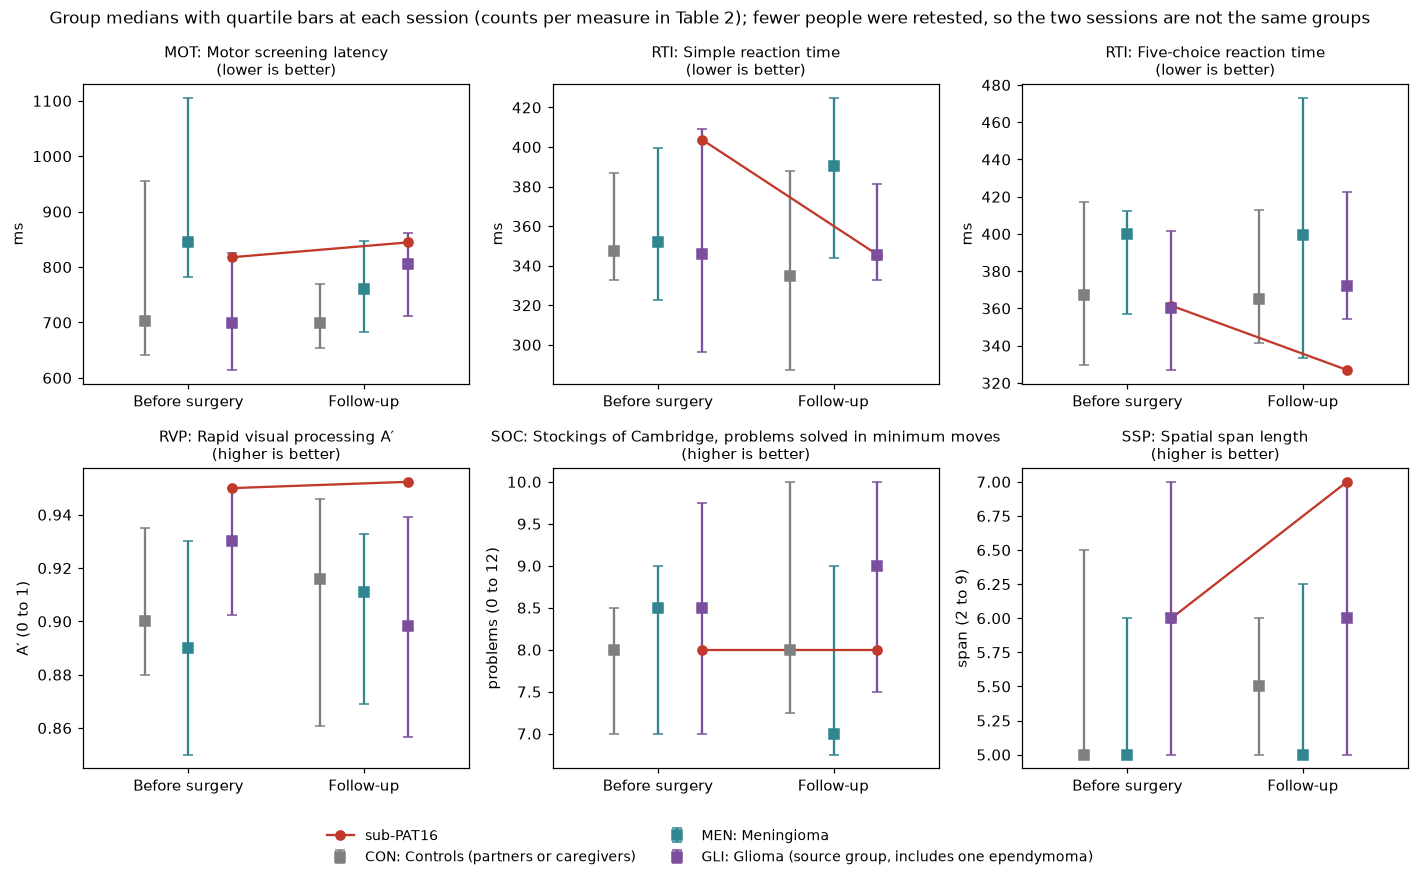

In [8]:
import matplotlib.pyplot as plt

from glioma_ai.btc_cantab_figures import draw_case, draw_change_forest, draw_cohort
from glioma_ai.notebook_display import show_figure

if cohort is not None:
    figure = plt.figure(figsize=(13, 8))
    draw_cohort(figure, cohort)
    show_figure(figure)

**Figure 1. Group medians and quartiles at each session, with sub-PAT16 overlaid (red).** Each
panel is one measure in its own units; the title states whether higher or lower is better. Squares
are group medians and bars run from the first to the third quartile. Individual participants are not
shown.

**Reading Figure 1.**
- *Overlap.* The groups overlap widely on every measure, before surgery and at follow-up.
- *Unpaired medians mislead.* The glioma median motor latency is 699 ms before surgery (n 10) and
  805 ms at follow-up (n 7), but the three people missing at follow-up make the two medians
  incomparable. Section 7 uses pairs.
- *Ceilings.* RVP A′ medians lie around 0.9 and SSP medians at 5–6 boxes, with little room above.

**Cognitive neuroscience track.** Group overlap is expected: individual differences in cognition are
large compared with the effects of a lesion in a small group.

**Neuro-oncology and clinical track.** Median performance of these patients before surgery is close to
that of their partners. This matches the view that impairment is heterogeneous and often subtle on
short screening tests ([Goffinet et al. 2026](https://doi.org/10.1037/neu0001103)).

**Data-analysis and modelling track.** The figure is descriptive. Testing group differences at
n 7–14 per cell with six measures would have low power and many comparisons.

### What does `RTI_fiveRT` contain? A column audit

**Data-analysis and modelling track.** Column names are claims to be checked. The BTC tables contain
`RTI_fiveRT`, `RTI_fiveMT`, `RTI_fiveMT_mean` and `RTI_fiveMT_md`, where MT normally means movement
time. Two properties help: the median of an even number of whole-millisecond trials lies on a 0.5 ms
grid, whereas a mean usually does not; and columns that measure the same thing correlate strongly.

In [9]:
from glioma_ai.btc_cantab import RTI_AUDIT_COLUMNS, column_audit

if cohort is not None:
    audit = column_audit(cohort)
    rows = [
        [
            f"`{column}`",
            f"{audit['columns'][column]['median']:.1f}",
            f"{audit['columns'][column]['half_ms_grid']:.0%}",
            *[f"{audit['correlation'][column][other]:.2f}" for other in RTI_AUDIT_COLUMNS],
        ]
        for column in RTI_AUDIT_COLUMNS
    ]
    header = ["Column", "Median (ms)", "On the 0.5 ms grid"] + [
        f"r with `{other}`" for other in RTI_AUDIT_COLUMNS
    ]
    display(
        Markdown(
            f"**Table 3. Five-choice RTI columns before surgery, n = {audit['n']} complete rows.**"
            "\n\n" + markdown_table(header, rows)
        )
    )

**Table 3. Five-choice RTI columns before surgery, n = 35 complete rows.**

| Column | Median (ms) | On the 0.5 ms grid | r with `RTI_fiveRT` | r with `RTI_fiveMT` | r with `RTI_fiveMT_mean` | r with `RTI_fiveMT_md` |
| --- | --- | --- | --- | --- | --- | --- |
| `RTI_fiveRT` | 369.5 | 100% | 1.00 | 0.98 | 0.03 | 0.37 |
| `RTI_fiveMT` | 385.4 | 17% | 0.98 | 1.00 | 0.01 | 0.39 |
| `RTI_fiveMT_mean` | 444.9 | 26% | 0.03 | 0.01 | 1.00 | 0.15 |
| `RTI_fiveMT_md` | 440.0 | 100% | 0.37 | 0.39 | 0.15 | 1.00 |

**Reading Table 3.** `RTI_fiveRT` always lies on the 0.5 ms grid, as a median of the eight
five-choice trials would. `RTI_fiveMT` mostly does not, behaves like a mean, and correlates 0.98 with
`RTI_fiveRT` but about 0 with `RTI_fiveMT_mean`. The column called `RTI_fiveMT` therefore looks like
the mean *reaction* time, not a movement time. This is an inference from the data, not documented by
the source. It does not affect this notebook, which uses `RTI_fiveRT` as the OSF release does, but it
would matter for anyone modelling movement times.

## 3. The sub-PAT16 case

sub-PAT16 is a participant of the glioma group whose imaging, connectome and CANTAB scores the
digital-twin project uses ([project](https://github.com/arvidl/glioma-brain-digital-twin-public); notebook 12 builds the case's structural connectome from
the same public data). The OSF release identifies the same person as PAT16, without the BIDS prefix. That
crosswalk is an assumption, and Table 4 tests it: every released score must agree.

The cell below reads the OSF release if it is present. It never downloads data.

In [10]:
release_dir = Path(os.environ.get("CANTAB_OSF_DIR", root / "data/cantab/osf"))
release_rows = None
if (release_dir / "Data.csv").is_file():
    release_rows = read_release(release_dir)
    print(json.dumps(cohort_summary(release_rows), indent=2))
else:
    print("Empirical inputs absent. Run make cantab-fetch; no synthetic case substituted.")

{
  "evidence_type": "released_behavioral_observations",
  "n_rows": 39,
  "groups": {
    "GLI": {
      "baseline_rows": 11,
      "paired_by_measure": {
        "MOT_latency_mean": 7,
        "RTI_fiveRT": 7,
        "RVP_A": 7,
        "SOC_prob_minmoves": 7,
        "SSP_spanlength": 7
      },
      "complete_four_domains": 7
    },
    "MEN": {
      "baseline_rows": 17,
      "paired_by_measure": {
        "MOT_latency_mean": 15,
        "RTI_fiveRT": 15,
        "RVP_A": 14,
        "SOC_prob_minmoves": 15,
        "SSP_spanlength": 15
      },
      "complete_four_domains": 14
    },
    "CON": {
      "baseline_rows": 11,
      "paired_by_measure": {
        "MOT_latency_mean": 10,
        "RTI_fiveRT": 10,
        "RVP_A": 10,
        "SOC_prob_minmoves": 10,
        "SSP_spanlength": 10
      },
      "complete_four_domains": 10
    }
  },
  "mri_linkage_and_qc": "not_performed"
}


In [11]:
from glioma_ai.btc_cantab import (
    CASE,
    OSF_ID,
    case_scores,
    cross_source_agreement,
    read_twin_sessions,
)
from glioma_ai.cantab import assessment_interval

if cohort is not None:
    pat16 = case_scores(cohort)
    twin = read_twin_sessions(btc_dir / "sub-PAT16_sessions.tsv")
    osf_row = None
    if release_rows is not None:
        osf_row = next(row for row in release_rows if row["subID"] == OSF_ID[CASE])
    agreement = cross_source_agreement(pat16, twin, osf_row)
    rows = [
        [
            f"`{r['measure']}`",
            r["session"].removeprefix("ses-"),
            r["openneuro"],
            f"{r['twin']} ({r['twin_agreement']})",
            "not released" if r["osf"] is None else f"{r['osf']} ({r['osf_agreement']})",
        ]
        for r in agreement
    ]
    header = ["Column", "Session", "OpenNeuro (record)", "Digital-twin table", "OSF release"]
    display(
        Markdown(
            f"**Table 4. {CASE} in three sources.** Agreement is judged at the precision of the "
            "value being checked.\n\n" + markdown_table(header, rows)
        )
    )
    print(
        f"{CASE} (OpenNeuro): group {pat16['group']}, label {pat16['label']!r}, "
        f"location {pat16['location']}, tumour volume before surgery {pat16['size_cm3']} cm³"
    )
    if osf_row is not None:
        print(
            f"{OSF_ID[CASE]} (OSF): laterality {osf_row['lesion_lat']}, "
            f"residual lesion volume after resection {osf_row['lesion_vol_cm3_t2']} cm³, "
            f"{assessment_interval(osf_row)} days between the two assessments"
        )

**Table 4. sub-PAT16 in three sources.** Agreement is judged at the precision of the value being checked.

| Column | Session | OpenNeuro (record) | Digital-twin table | OSF release |
| --- | --- | --- | --- | --- |
| `MOT_latency_mean` | preop | 817.8 | 817.8 (exact) | 817.8 (exact) |
| `MOT_latency_mean` | postop | 844.5 | 844.5 (exact) | 844.5 (exact) |
| `RTI_simpleRT_mean` | preop | 403.78 | 403.78 (exact) | not released |
| `RTI_simpleRT_mean` | postop | 345.5555555556 | 345.5555555556 (exact) | not released |
| `RTI_fiveRT` | preop | 361.5 | 361.5 (exact) | 361.5 (exact) |
| `RTI_fiveRT` | postop | 327 | 327 (exact) | 327 (exact) |
| `RVP_A` | preop | 0.95 | 0.95 (exact) | 0.95 (exact) |
| `RVP_A` | postop | 0.9523552615 | 0.9523552615 (exact) | 0.95 (at_release_precision) |
| `SOC_prob_minmoves` | preop | 8 | 8 (exact) | 8 (exact) |
| `SOC_prob_minmoves` | postop | 8 | 8 (exact) | 8 (exact) |
| `SSP_spanlength` | preop | 6 | 6 (exact) | 6 (exact) |
| `SSP_spanlength` | postop | 7 | 7 (exact) | 7 (exact) |

sub-PAT16 (OpenNeuro): group GLI, label 'Anaplastic astrocytoma II-III', location Fronto-temporal, tumour volume before surgery 50.24 cm³
PAT16 (OSF): laterality Right, residual lesion volume after resection 18.614 cm³, 246 days between the two assessments


The availability summary above counts the OSF release, which has 17 meningioma rows where BTC has
14: the behavioural and MRI cohorts of the same study differ, so linking them needs an explicit ID
crosswalk.

**Reading Table 4.** All values agree. The digital-twin table copies OpenNeuro exactly. OSF agrees
exactly except for RVP A′ at follow-up, released as 0.95 where OpenNeuro holds 0.9523552615; the two
agree at the OSF release's two-decimal precision (section 5 explains what that means). OSF does not
release simple reaction time.

**The case.** A tumour labelled "Anaplastic astrocytoma II-III", fronto-temporal and right-sided, with
a volume of 50.24 cm³ before surgery, larger than the third quartile of the glioma group (Table 2).
The residual lesion volume after resection was 18.6 cm³ according to the OSF legend, and the two
assessments were 246 days apart. Exact dates, age and sex are not shown.

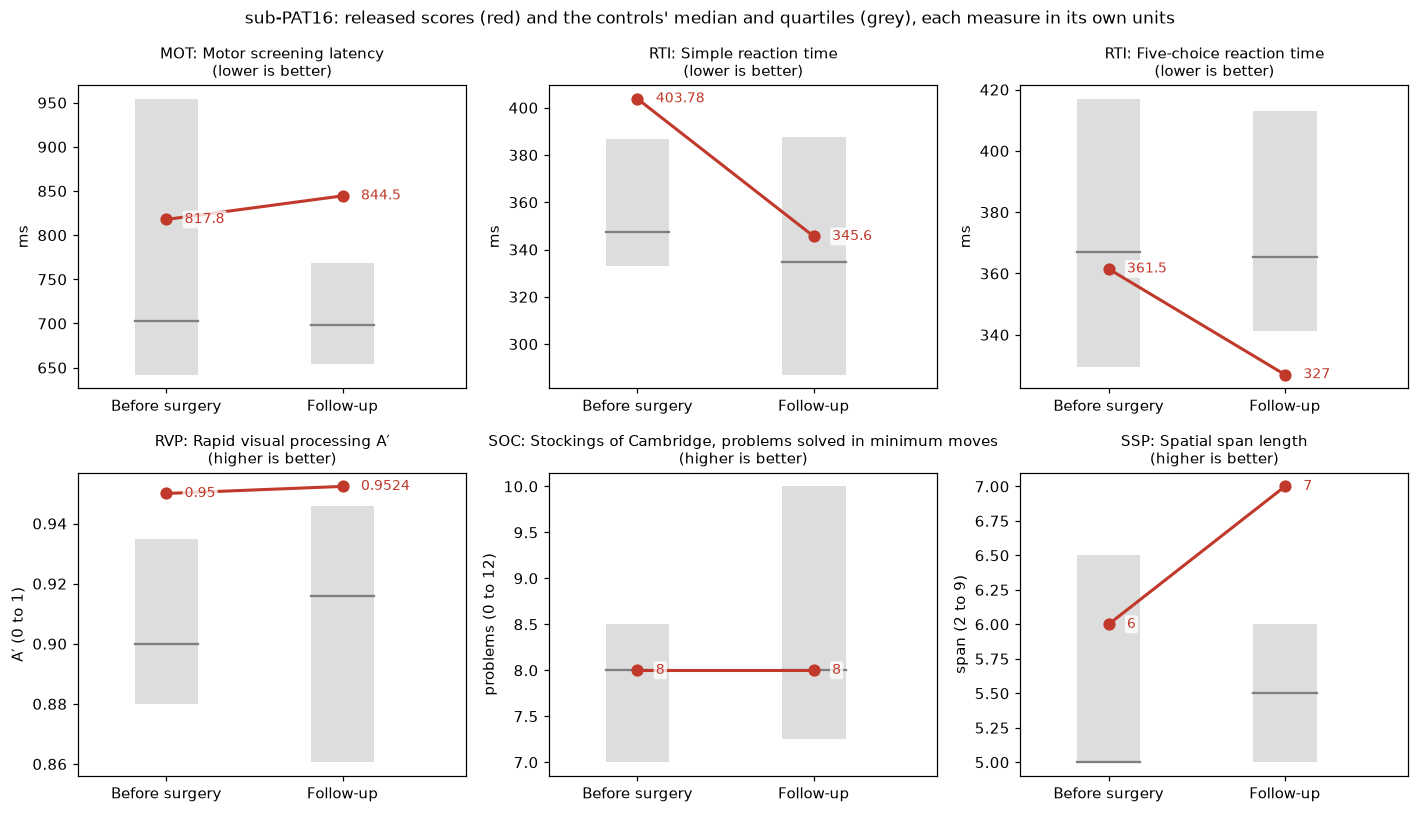

In [12]:
if cohort is not None:
    figure = plt.figure(figsize=(13, 7.5))
    draw_case(figure, cohort)
    show_figure(figure)

**Figure 2. sub-PAT16's scores (red) against the controls' median (grey line) and quartiles (grey
band) at each session.** Released values are printed next to the points.

**Reading Figure 2.**
- *Motor screening:* 817.8 → 844.5 ms, slower.
- *Simple reaction time:* 403.8 → 345.6 ms, faster. *Five-choice:* 361.5 → 327 ms, faster.
- *RVP A′:* 0.95 → 0.952, at the ceiling and above the controls' third quartile at both sessions.
- *SOC:* 8 → 8 problems. *SSP:* 6 → 7 boxes, above the controls' median at both sessions.

Whether any of these differences exceeds what repeated testing alone produces is the subject of
sections 6 and 7. Before that, section 4 checks an AI-generated summary of the same numbers.

The cell below reproduces, from the OSF release and an ignored local configuration, the verified case
figure used in the paper ([preparation](../../docs/cantab-example.md)).

[
  {
    "measure": "MOT_latency_mean",
    "visit": 1,
    "agreement": "exact"
  },
  {
    "measure": "MOT_latency_mean",
    "visit": 2,
    "agreement": "exact"
  },
  {
    "measure": "RTI_fiveRT",
    "visit": 1,
    "agreement": "exact"
  },
  {
    "measure": "RTI_fiveRT",
    "visit": 2,
    "agreement": "exact"
  },
  {
    "measure": "RVP_A",
    "visit": 1,
    "agreement": "exact"
  },
  {
    "measure": "RVP_A",
    "visit": 2,
    "agreement": "at_release_precision"
  },
  {
    "measure": "SOC_prob_minmoves",
    "visit": 1,
    "agreement": "exact"
  },
  {
    "measure": "SOC_prob_minmoves",
    "visit": 2,
    "agreement": "exact"
  },
  {
    "measure": "SSP_spanlength",
    "visit": 1,
    "agreement": "exact"
  },
  {
    "measure": "SSP_spanlength",
    "visit": 2,
    "agreement": "exact"
  }
]


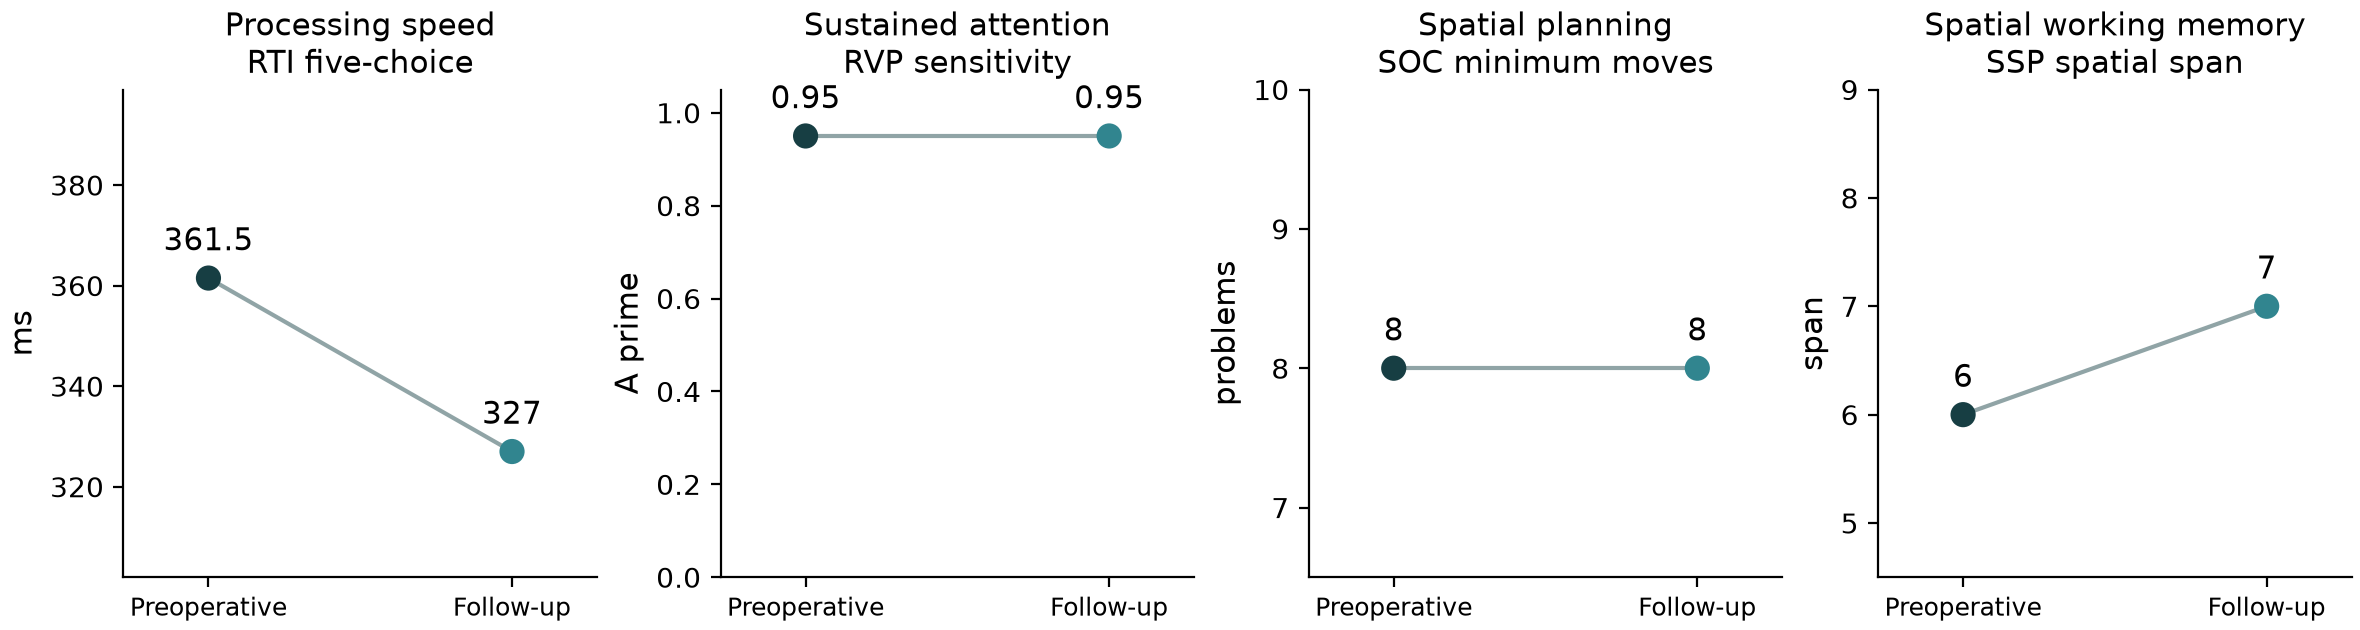

Assessment interval (days): 246
Interpretation: descriptive at release precision; reliable change not assessed


In [13]:
case_config = Path(os.environ.get("CANTAB_CASE_CONFIG", root / "local/cantab-case.json"))
if release_rows is not None and case_config.is_file():
    from IPython.display import Image

    out = root / "outputs/cantab"
    report = write_cantab_example(release_dir, out, case_config)
    print(json.dumps(report["case_audit"], indent=2))
    display(Image(filename=str(out / "cantab_case.png")))
    case = json.loads((out / "cantab_case.json").read_text())
    print("Assessment interval (days):", case["assessment_interval_days"])
    print("Interpretation:", case["interpretation"])
else:
    print("Case not run: supply verified source files and explicit local case configuration.")

## 4. Audit an infographic

Generative AI tools produce fluent text and polished graphics quickly, and they can also produce
numbers, labels and conclusions that look right but are not supported by the source. Such output is
often called a *hallucination*. It is hard to spot because the layout, the units and the confident
wording look as they should. The only reliable check is to compare every number with the source.

The investigator supplied a slide, "CANTAB Cognitive Assessment: sub-PAT16 Pre-op vs Post-op"
(Figure 3), generated with an AI assistant for a presentation. How its numbers arose is not known.
It has bars of raw scores, a panel of percentage changes and written conclusions.

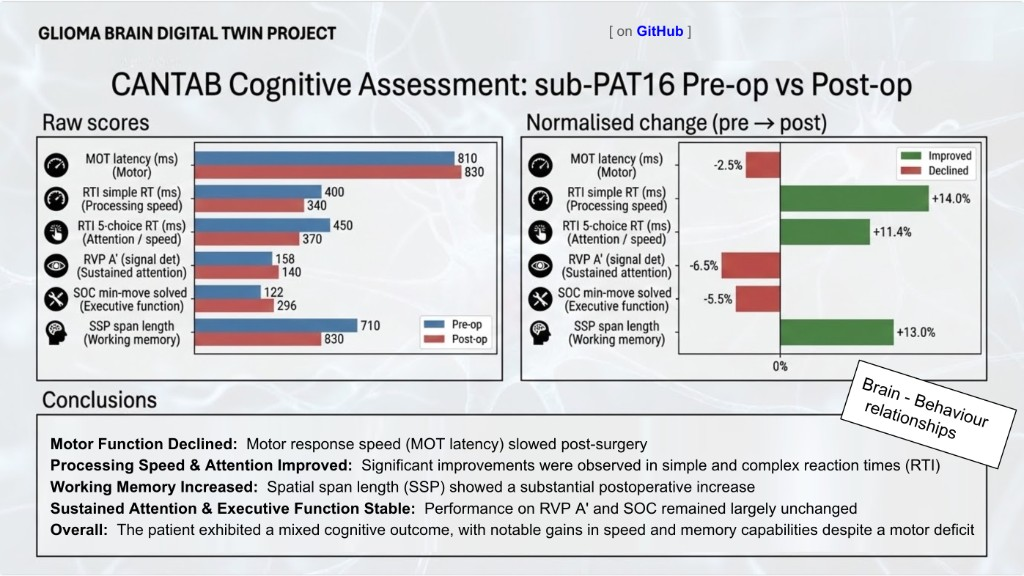

**Figure 3. The AI-generated slide, unmodified (it contains errors; see Table 5).** Do not reuse its
numbers. Image supplied by the investigator, 14 October 2026.

The slide's values below were transcribed by the assistant from the slide image (14 October 2026).
Auditing it is an exercise in reading any summary, whether made by a person or generated by
software, against its source.

The slide's conclusions, quoted: "Significant improvements were observed in simple and complex
reaction times (RTI)"; "Spatial span length (SSP) showed a substantial postoperative increase";
"Performance on RVP A′ and SOC remained largely unchanged"; "Motor response speed (MOT latency) slowed
post-surgery".

In [14]:
from glioma_ai.btc_cantab import audit_reported

SLIDE_AS_TRANSCRIBED = {
    "MOT_latency_mean": {"values": (810, 830), "percent": -2.5},
    "RTI_simpleRT_mean": {"values": (400, 340), "percent": 14.0},
    "RTI_fiveRT": {"values": (450, 370), "percent": 11.4},
    "RVP_A": {"values": (158, 140), "percent": -6.5},
    "SOC_prob_minmoves": {"values": (122, 296), "percent": -5.5},
    "SSP_spanlength": {"values": (710, 830), "percent": 13.0},
}
if cohort is not None:
    rows = [
        [
            MEASURES[r["measure"]]["short"],
            MEASURES[r["measure"]]["unit"],
            "{} → {}".format(*r["reported"]),
            "{:.4g} → {:.4g}".format(*r["source"]),
            "yes" if r["within_scale"] else "**no**",
            f"{r['reported_percent']:+.1f}%",
            f"{r['percent_from_reported_values']:+.1f}%",
            f"{r['percent_from_source']:+.1f}%",
        ]
        for r in audit_reported(SLIDE_AS_TRANSCRIBED, pat16)
    ]
    header = [
        "Measure",
        "Unit and scale",
        "Slide",
        "Source",
        "Slide values possible?",
        "Slide %",
        "% from slide's own bars",
        "% from source",
    ]
    display(
        Markdown(
            "**Table 5. The slide against the source.** Percentages are signed so that positive "
            "means better in the measure's own direction.\n\n" + markdown_table(header, rows)
        )
    )

**Table 5. The slide against the source.** Percentages are signed so that positive means better in the measure's own direction.

| Measure | Unit and scale | Slide | Source | Slide values possible? | Slide % | % from slide's own bars | % from source |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Motor latency | ms | 810 → 830 | 817.8 → 844.5 | yes | -2.5% | -2.5% | -3.3% |
| Simple reaction time | ms | 400 → 340 | 403.8 → 345.6 | yes | +14.0% | +15.0% | +14.4% |
| Five-choice reaction time | ms | 450 → 370 | 361.5 → 327 | yes | +11.4% | +17.8% | +9.5% |
| RVP A′ | A′ (0 to 1) | 158 → 140 | 0.95 → 0.9524 | **no** | -6.5% | -11.4% | +0.2% |
| SOC minimum-move problems | problems (0 to 12) | 122 → 296 | 8 → 8 | **no** | -5.5% | +142.6% | +0.0% |
| Spatial span | span (2 to 9) | 710 → 830 | 6 → 7 | **no** | +13.0% | +16.9% | +16.7% |

**Reading Table 5.**
- *Impossible values.* RVP A′ cannot exceed 1, SOC counts at most 12 problems and SSP spans at most
  9 boxes; the slide shows 158, 296 and 830. These bars cannot be the named measures.
- *Wrong values.* Five-choice reaction time is 361.5 → 327 ms in all three sources, not 450 → 370.
  Motor and simple reaction time are approximately right.
- *Percentages that contradict their own bars.* SOC rising from 122 to 296 would be +143%, but the
  slide prints −5.5%; its five-choice +11.4% matches neither its own bars (+17.8%) nor the source
  (+9.5%).
- *Unsupported "significant".* No test is named. Section 7 finds no change index beyond the
  conventional threshold in the main analysis.
- *Percentages of bounded or count scores.* "+13%" for SSP describes one extra box (6 → 7, +16.7% in
  the source); expressing it as a percentage invites comparison with reaction times, which have a
  different scale and reliability.
- *What is right.* Motor slowing is correctly called a decline (higher latency is worse), and RVP and
  SOC are indeed unchanged in the source, although the slide's own bars contradict that statement.

Figure 4 redraws the slide from the released scores.

### A reconstruction that can be verified

Figure 4 keeps the slide's three parts and colours, with four changes that make it checkable:
- *Each bar is a fraction of its own axis.* The three timed tests share one 0–1000 ms axis; A′, SOC
  and SSP are drawn against their full scales (0–1, 0–12, 2–9), so one box of spatial span looks as
  small as it is. Values are printed in native units.
- *The direction of "better" is stated per measure,* because a longer bar means worse for times.
- *Each percentage carries the largest of the three change indices* of section 7, so a large
  percentage cannot pass as a large change.
- *The conclusions are generated by code* from those indices, not written by hand. A change is
  called reliable only when all three indices exceed ±1.96 in the same direction.

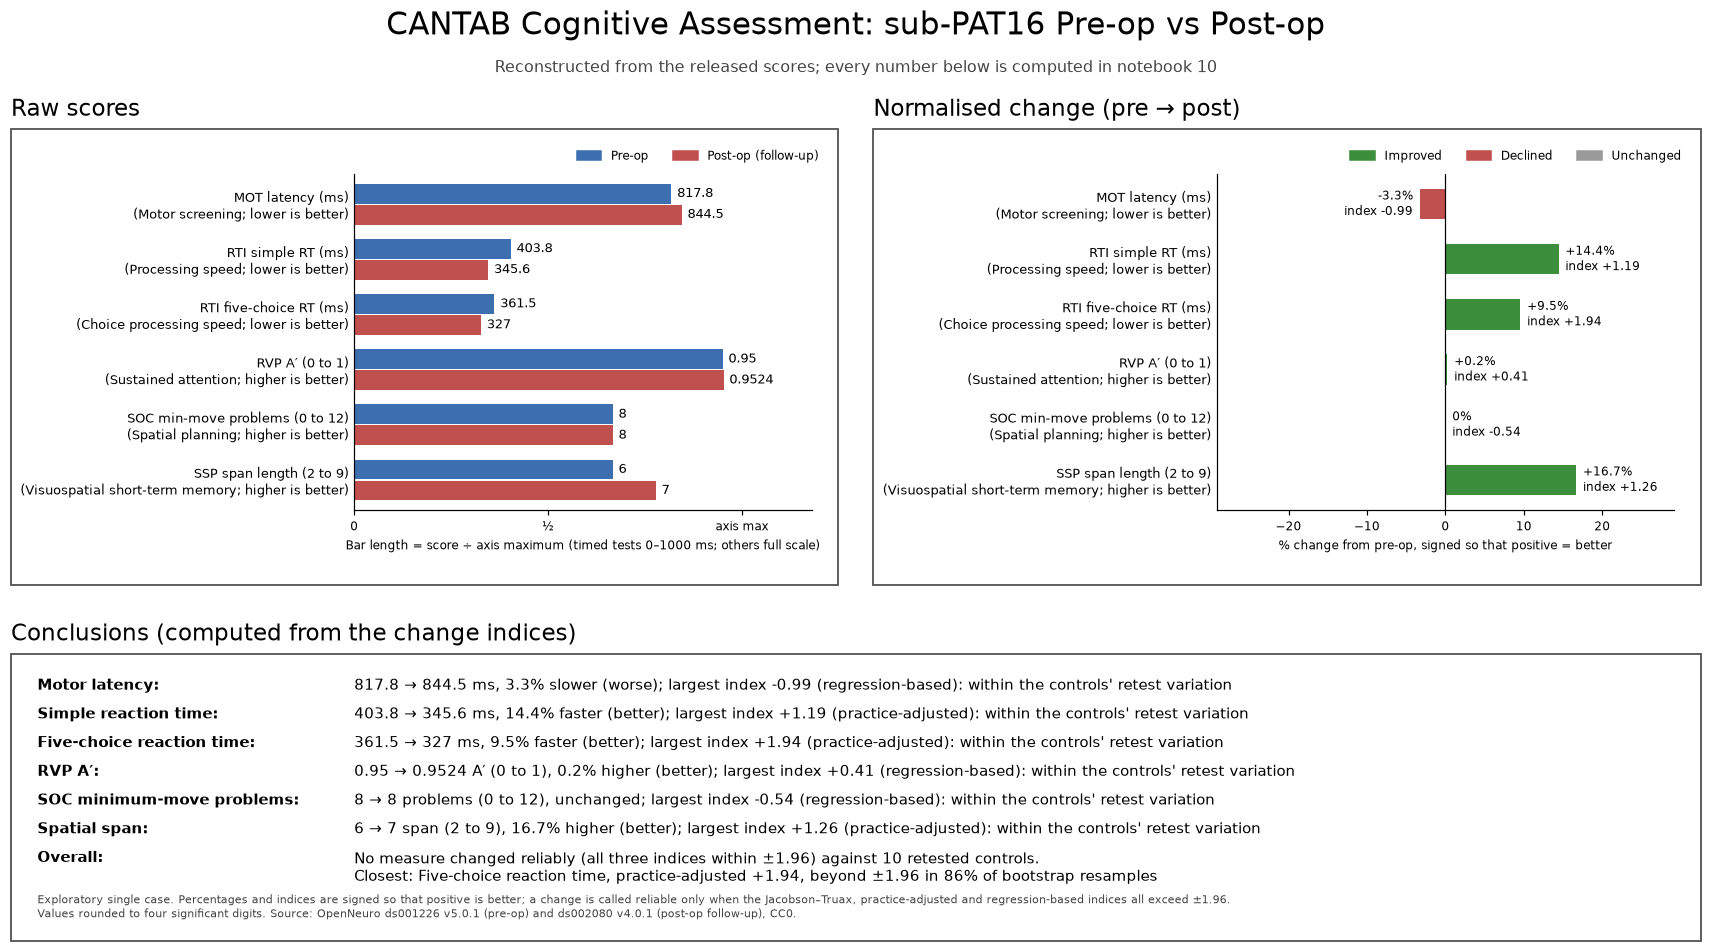

In [15]:
from glioma_ai.btc_cantab import case_change_table
from glioma_ai.btc_cantab_figures import draw_infographic

if cohort is not None:
    figure = plt.figure(figsize=(16, 9))
    draw_infographic(figure, cohort, case_change_table(cohort))
    show_figure(figure)

**Figure 4. The slide reconstructed from the released scores (OpenNeuro ds001226 and ds002080).**
Every number is computed in this notebook from the pinned files; the indices and their bootstrap are
explained in sections 6 and 7.

**Reading Figure 4 against Figure 3.**
- *Raw scores:* motor latency and simple reaction time are close to the slide. Five-choice reaction
  time is 361.5 → 327 ms, not 450 → 370. RVP A′, SOC and SSP are 0.95 → 0.952, 8 → 8 and 6 → 7, on
  scales on which the slide's 158, 296 and 830 cannot occur.
- *Percentages:* RVP and SOC are unchanged, not declines of 6.5% and 5.5%. Spatial span is +16.7%,
  which is one box.
- *Conclusions:* none of the six changes exceeds the controls' retest variation on all three
  indices. The slide's "significant improvements" and "substantial increase" are not supported. The
  closest case, five-choice reaction time, is examined in section 7.

## 5. Precision: how many digits can be trusted?

A released score such as 0.70 carries two decimal places. A local copy reading 0.702 is *compatible*
with it (it rounds to 0.70), but the extra digit is not verified by the release, and a small apparent
improvement within that rounding interval is not evidence of anything. A local value of 0.72 is a
mismatch. The numbers in the next cell are made up for the check; they are not patient observations.
Table 4 contains a real instance: sub-PAT16's RVP A′ at follow-up is 0.95 in the OSF release and
0.9523552615 in OpenNeuro.

In [16]:
assert precision_agreement("0.70", "0.702") == "at_release_precision"
assert precision_agreement("0.70", "0.72") == "mismatch"
assert precision_agreement("0.70", "0.700") == "exact"
print("Synthetic precision checks passed. These are not patient observations.")

Synthetic precision checks passed. These are not patient observations.


Things to try in the explorer below:
1. Released `0.70`, local `0.705`, then `0.715`. Half-even rounding decides the boundary case.
2. Released `0.7` instead of `0.70`. The interval widens tenfold: trailing zeros carry information.
3. Released `12`, local `12.4`. What does a whole-number release say about a decimal local value?

In [17]:
from glioma_ai.cantab_interactive import precision_explorer

precision_explorer()

## 6. When is a change real? Reliable change indices

Repeating a test gives a slightly different score even if nothing has changed. Jacobson and Truax
([J Consult Clin Psychol 1991](https://doi.org/10.1037/0022-006X.59.1.12)) asked whether a change exceeds what that measurement error
would produce:

$$SEM=SD\sqrt{1-r},\qquad S_{\text{diff}}=\sqrt{2}\,SEM,\qquad
RCI_{\text{JT}}=\frac{x_2-x_1}{S_{\text{diff}}}.$$

Two refinements are used in section 7.

*Practice-adjusted* ([Chelune et al. 1993](https://doi.org/10.1037/0894-4105.7.1.41)): subtract the mean change $\bar d$ of a
reference sample retested over a similar interval,
$$RCI_{\text{PA}}=\frac{(x_2-x_1)-\bar d}{S_{\text{diff}}}.$$

*Regression-based* ([McSweeny et al. 1993](https://doi.org/10.1080/13854049308401901)): predict the follow-up score from the
baseline score with a line fitted in the reference sample, and scale the residual by the standard
error of estimate $SEE$ of that fit,
$$z_{\text{RB}}=\frac{x_2-(a+b\,x_1)}{SEE}.$$
This allows for practice, for regression to the mean and for different spreads at the two sessions.

| Symbol | Meaning |
| --- | --- |
| $x_1, x_2$ | the person's baseline and follow-up scores |
| $SD$ | standard deviation at baseline in a compatible reference sample |
| $r$ | test–retest correlation in that sample |
| $\bar d$ | mean follow-up minus baseline in that sample (practice) |
| $a, b, SEE$ | intercept, slope and residual standard deviation of follow-up on baseline in that sample |

$|RCI|>1.96$ is conventionally called reliable at the two-sided 5% level. Whether a reliable change is
an improvement or a decline depends on the measure's direction (Table 1).

**Neuro-oncology and clinical track.** Reliable is not the same as clinically meaningful. Jacobson and
Truax also asked whether a person moves into the range of well-functioning people; a reliable change
can be too small to matter in daily life, and a meaningful one can be missed by an unreliable test.

**Cognitive neuroscience track.** Reliability is not a property of a test alone. It depends on how
stable the measured process is over the interval, on the population and on ceilings: a test at its
ceiling cannot show improvement however reliable it is.

**Data-analysis and modelling track.** The indices assume roughly normal errors, a reference sample
from the same population, the same interval and no change in the reference people. The reference
statistics are estimates; with ten people they are imprecise.

**Every number in the rest of this section and its explorer is hypothetical.**

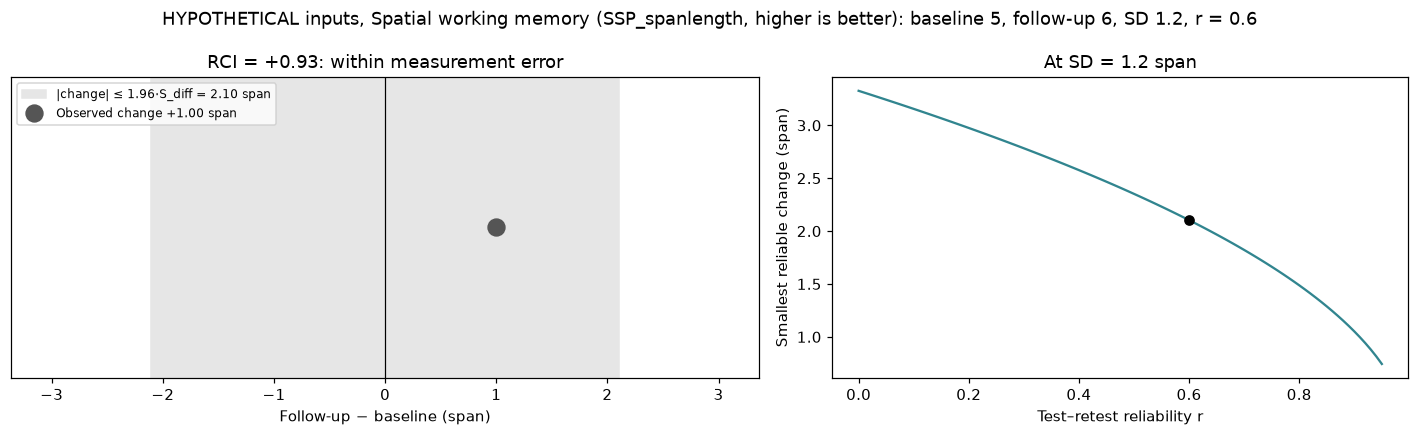

HYPOTHETICAL: SE = 0.76, S_diff = 1.07, RCI = 0.93; a reliable change would need at least 2.10 span.


In [18]:
import matplotlib.pyplot as plt

from glioma_ai.cantab_interactive import change_scenario, draw_change_state
from glioma_ai.notebook_display import show_figure

example = change_scenario(
    "SSP_spanlength", baseline=5, follow_up=6, baseline_sd=1.2, reliability=0.6
)
figure = plt.figure(figsize=(13, 4))
draw_change_state(figure, example)
show_figure(figure)
print(
    f"HYPOTHETICAL: SE = {example['standard_error']:.2f}, S_diff = {example['s_diff']:.2f}, "
    f"RCI = {example['rci']:.2f}; a reliable change would need at least "
    f"{example['minimum_reliable_change']:.2f} span."
)

**Figure 5. A one-box gain in spatial span is within measurement error under these hypothetical
inputs.** Left: the observed change (+1 box) lies inside the grey band of changes smaller than
1.96·S_diff. Right: the smallest reliable change falls as test–retest reliability rises; with r = 0.6 and
SD = 1.2 boxes it is 2.1 boxes.

Things to try in the explorer below:
1. With spatial span, raise the reliability to 0.9. Does +1 box become reliable? What would you need to
   know about the test to justify r = 0.9?
2. Choose `RTI_fiveRT`. A lower reaction time is better: check that a faster follow-up is labelled an
   improvement.
3. Double the SD. The band doubles. Why does a heterogeneous reference sample make individual change
   harder to detect?

In [19]:
from glioma_ai.cantab_interactive import change_explorer

change_explorer()

## 7. sub-PAT16 against the retested controls (exploratory)

**Why exploratory.** The only retest data in this cohort are the ten controls with both sessions.
They supply $SD$, $r$, $\bar d$, $a$, $b$ and $SEE$ for each measure. They are partners of patients,
not a normative sample, their retest interval is not matched to sub-PAT16's 246 days, and ten people
give imprecise estimates. The bootstrap resamples the ten controls 4,000 times (seed 20261014) and
recomputes every index, showing how much the verdict depends on who happens to be in the reference.

**Table 6. Change indices for sub-PAT16 against the retested controls.** Indices are oriented so that positive means better; practice and SD are in the measure's units.

| Measure | Controls n | r | Practice (mean change) | SD | sub-PAT16 | Jacobson–Truax | Practice-adjusted | Regression-based | Bootstrap share beyond 1.96 (practice-adjusted) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Motor latency, ms | 10 | 0.75 | -52.2 | 240 | 817.8 → 844.5 | -0.16 | -0.46 | -0.99 | 2% |
| Simple reaction time, ms | 10 | 0.54 | +2.09 | 52.5 | 403.8 → 345.6 | +1.15 | +1.19 | +0.66 | 13% |
| Five-choice reaction time, ms | 10 | 0.71 | +44.6 | 53.5 | 361.5 → 327 | +0.84 | +1.94 | +0.97 | 86% |
| RVP A′, A′ (0 to 1) | 10 | 0.64 | -0.00389 | 0.044 | 0.95 → 0.9524 | +0.06 | +0.17 | +0.41 | 1% |
| SOC minimum-move problems, problems (0 to 12) | 10 | 0.70 | +0.8 | 1.99 | 8 → 8 | +0.00 | -0.52 | -0.54 | 0% |
| Spatial span, span (2 to 9) | 10 | 0.71 | -0.2 | 1.25 | 6 → 7 | +1.05 | +1.26 | +1.18 | 19% |

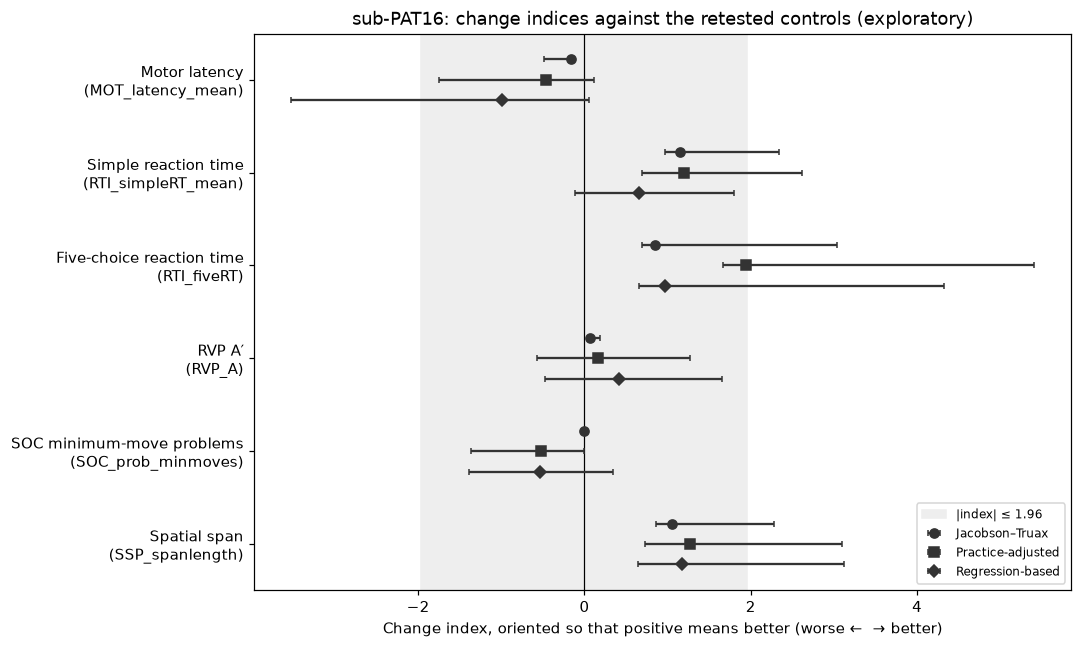

In [20]:
from glioma_ai.btc_cantab import INDICES, case_change_table

if cohort is not None:
    change = case_change_table(cohort)
    rows = []
    for r in change:
        spec = MEASURES[r["measure"]]
        if not r["defined"]:
            rows.append([spec["short"], *["undefined"] * 9])
            continue
        s, sense = r["reference"], r["sense"]
        rows.append(
            [
                f"{spec['short']}, {spec['unit']}",
                s["n"],
                f"{s['r']:.2f}",
                f"{s['practice']:+.3g}",
                f"{s['sd_baseline']:.3g}",
                f"{r['baseline']:.4g} → {r['follow_up']:.4g}",
                *[f"{sense * r[name]:+.2f}" for name in INDICES],
                f"{r['bootstrap']['share_beyond_threshold']['practice_adjusted']:.0%}",
            ]
        )
    header = [
        "Measure",
        "Controls n",
        "r",
        "Practice (mean change)",
        "SD",
        CASE,
        *INDICES.values(),
        "Bootstrap share beyond 1.96 (practice-adjusted)",
    ]
    display(
        Markdown(
            "**Table 6. Change indices for sub-PAT16 against the retested controls.** "
            "Indices are oriented so that positive means better; practice and SD are in the "
            "measure's units.\n\n" + markdown_table(header, rows)
        )
    )
    figure = plt.figure(figsize=(10, 6))
    draw_change_forest(figure, change)
    show_figure(figure)

**Figure 6. sub-PAT16's three change indices per measure, with 95% bootstrap intervals from
resampling the controls.** Right of zero is better. The grey band marks |index| ≤ 1.96; points
outside it would be drawn red.

**Reading Table 6 and Figure 6.**
- *No index exceeds 1.96 in the main analysis.* The largest is the practice-adjusted index for
  five-choice reaction time, +1.94. The controls became *slower* at retest (mean +44.6 ms), while
  sub-PAT16 became 34.5 ms faster, so adjusting for the controls' change enlarges the case's
  improvement.
- *The verdict is fragile.* 86% of bootstrap resamples put that index beyond 1.96. In the explorer
  below, leaving out the one control whose five-choice time changed most raises r from 0.71 to 0.91,
  and the practice-adjusted and regression-based indices become about +2.5, a "reliable improvement".
  One person in ten decides the label.
- *Spatial span +1 box* gives indices of 1.05–1.26, within the controls' variation under all three.
- *Many chances.* With six measures, the chance that at least one of six independent indices exceeds
  1.96 by chance alone is $1-0.95^6\approx26\%$; choosing among three indices afterwards raises it
  further.

**Neuro-oncology and clinical track.** A careful report would read: five-choice and simple reaction
times were faster at follow-up and motor screening slower; under the classic index all changes were
within the variation seen in retested partners, and the reaction-time improvement was borderline and
not robust after adjusting for practice. Nothing here attributes a change to surgery: 246 days also
include recovery, possible adjuvant treatment, medication and mood changes.

**Cognitive neuroscience track.** Faster decisions (reaction time excludes movement) together with
slower motor screening (which includes movement) is a dissociation worth asking about, not a finding.
The movement-time columns, after the audit of section 2, would be the next variables to examine.

**Data-analysis and modelling track.** This is a forking-paths example: the label depends on the index,
on one reference person and on the threshold. A defensible analysis fixes the index, the reference
sample and the handling of outliers before looking at the patient, and reports the bootstrap
interval rather than a yes-or-no label.

### Explore the robustness of the verdict

Choose a measure and leave out the control with the largest retest change. The left panel shows
sub-PAT16's change in native units against the controls' changes (median and quartiles) and the
practice-adjusted band; the right panel shows the three indices with bootstrap intervals. Which
apparent changes survive, and which disappear?

Things to try:
1. `RTI_fiveRT` with and without the extreme control. Why does one person move r from 0.71 to 0.91?
2. `SSP_spanlength`. Integer scores: how many distinct changes did the controls show?
3. `RVP_A`. Why is the Jacobson–Truax interval so narrow, while the others are wide?

In [21]:
from glioma_ai.btc_cantab_figures import change_explorer as cohort_change_explorer

if cohort is not None:
    display(cohort_change_explorer(cohort))

## 8. Clinical interpretation: what the tables can and cannot say

**Neuro-oncology and clinical track.**
- *The tumour.* A right fronto-temporal diffuse glioma of 50 cm³, labelled grade II–III with older
  histological terms. Without IDH and 1p/19q status it cannot be placed in the 2021 classification
  ([Louis et al. 2021](https://doi.org/10.1093/neuonc/noab106)); IDH status is associated with cognitive phenotype and outcome
  ([Reyes et al. 2025](https://doi.org/10.1093/neuonc/noae183); [Cayuela et al. 2025](https://doi.org/10.1093/noajnl/vdaf003)).
- *The interval.* 246 days between assessments; the date of surgery relative to each assessment is
  not in these tables. Adjuvant radiotherapy or chemotherapy, antiseizure drugs, corticosteroids,
  seizures, fatigue and sleep are not recorded here; anxiety and mood questionnaires are, but are
  not shown under the privacy decision.
- *Residual lesion.* 18.6 cm³ after resection, according to the OSF legend; residual infiltrating
  tumour continues to interact with networks ([Salvalaggio et al. 2025](https://doi.org/10.1097/CCO.0000000000001190)).
- *Right hemisphere.* Language is less likely to be affected than with a left-sided tumour;
  attention and visuospatial networks may be, but tumour effects are distributed rather than local
  ([Houskamp et al. 2025](https://doi.org/10.3390/cancers17172775); [Herbet 2024](https://doi.org/10.1093/brain/awae093)).
- *Meningioma versus glioma.* The same tests and the same caregiver comparison group are used for
  tumours with very different biology; meningioma resection often improves cognition
  ([Barne et al. 2025](https://doi.org/10.1016/j.wneu.2024.11.102)), whereas glioma resection removes infiltrated tissue among
  functioning networks.

**What would be needed for a clinical statement.** Normative and retest data for the same tests,
population and interval; a full neuropsychological battery including memory and language; treatment
and medication records; and serial assessments rather than two points. Harmonised batteries and
reporting were recommended long ago ([Wefel et al. 2011](https://doi.org/10.1016/S1470-2045(10)70294-1)) and are still argued for
([Karagianni et al. 2026](https://doi.org/10.1016/j.bas.2026.106663)).

## 9. Forecasting follow-up scores (modelling track)

**Data-analysis and modelling track.** Before predicting cognition after surgery from images,
connectomes or a digital twin, ask how well trivial rules do. Three leave-one-out forecasts of each
person's follow-up score, each fitted without that person:
- *persistence:* follow-up = baseline;
- *mean change:* baseline plus the others' mean change;
- *regression:* a line of follow-up on baseline fitted to the others.

Table 7 reports the mean absolute error in the measure's units, pooling all retested participants and
for controls alone.

In [22]:
from glioma_ai.btc_cantab import forecast_table

if cohort is not None:
    names = ("persistence", "mean_change", "regression")
    rows = []
    tables = forecast_table(cohort), forecast_table(cohort, ("CON",))
    for pooled, controls in zip(*tables, strict=True):
        cells = []
        for result in (pooled, controls):
            best = min(names, key=result.get)
            cells.append(result["n"])
            cells += [f"{result[name]:.3g}" for name in names]
            cells[-3 + names.index(best)] = f"**{cells[-3 + names.index(best)]}**"
        rows.append([MEASURES[pooled["measure"]]["short"], pooled["unit"], *cells])
    labels = ["persistence", "mean change", "regression"]
    header = [
        "Measure",
        "Unit",
        "All groups n",
        *[f"All: {label}" for label in labels],
        "Controls n",
        *[f"Controls: {label}" for label in labels],
    ]
    display(
        Markdown(
            "**Table 7. Leave-one-out mean absolute error of three simple forecasts** "
            "(lowest per row and sample in bold).\n\n" + markdown_table(header, rows)
        )
    )

**Table 7. Leave-one-out mean absolute error of three simple forecasts** (lowest per row and sample in bold).

| Measure | Unit | All groups n | All: persistence | All: mean change | All: regression | Controls n | Controls: persistence | Controls: mean change | Controls: regression |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Motor latency | ms | 29 | 142 | 152 | **121** | 10 | 118 | 131 | **72.9** |
| Simple reaction time | ms | 29 | **54.8** | 56.6 | 56.4 | 10 | **41.9** | 46.9 | 47.8 |
| Five-choice reaction time | ms | 29 | 61.2 | **59.6** | 61.5 | 10 | **47.5** | 52.7 | 72 |
| RVP A′ | A′ (0 to 1) | 28 | **0.031** | 0.0324 | 0.0326 | 10 | **0.03** | 0.0334 | 0.0378 |
| SOC minimum-move problems | problems (0 to 12) | 29 | 1.72 | 1.78 | **1.43** | 10 | **1.2** | 1.33 | 1.26 |
| Spatial span | span (2 to 9) | 29 | **0.724** | 0.793 | 0.811 | 10 | **0.8** | 0.933 | 0.955 |

**Reading Table 7.** Persistence is hard to beat. Pooling all 28–29 retested participants, it has
the lowest error for simple reaction time, RVP A′ and spatial span; regression wins for motor latency
and SOC, and mean change by a small margin for five-choice reaction time. In controls alone,
persistence wins everywhere except motor latency. For spatial span, persistence errs by 0.72 boxes on
average and regression by 0.81: with test–retest correlations around 0.7, most of the follow-up score
is already in the baseline score.

**Implications.**
- A model of cognition after surgery should be compared with persistence on the same held-out people
  and in the same units, as proposed in the [study design](../../docs/cognition-prediction-study.md).
- With 29 people, differences of a few milliseconds or a fraction of a box between rules are within
  noise. Sample size calculations for prediction models routinely require far more participants
  ([Riley et al. 2025](https://doi.org/10.1016/j.landig.2025.01.013)), and reporting should follow TRIPOD+AI
  ([Collins et al. 2024](https://doi.org/10.1136/bmj-2023-078378)).
- Predictors must exist before surgery. Postoperative imaging, residual volume and later treatment
  cannot enter a preoperative forecast.

**Cognitive neuroscience track.** A mechanistic model, such as The Virtual Brain with a
patient-specific connectome ([Aerts et al. 2018](https://doi.org/10.1523/ENEURO.0083-18.2018), [2020](https://doi.org/10.1016/j.neuroimage.2020.116738); notebook 12 for
sub-PAT16's connectome), is valuable if it explains *why* scores change, but as a forecaster it must
still beat persistence.

**Neuro-oncology and clinical track.** For counselling a patient, "your scores will probably be
similar to now" is the honest default forecast from these data; anything more specific needs
validation in a larger cohort.

## 10. Networks, mechanisms and the limits of CANTAB

**Cognitive neuroscience track.**
- *Networks rather than spots.* Cognitive effects of glioma are increasingly described at the network
  level, from tumour biology to symptoms and survival ([Douw et al. 2026](https://doi.org/10.1038/s41582-025-01171-x)), and predictors
  of cognition after surgery include disconnection of white-matter pathways and plasticity
  ([Herbet 2024](https://doi.org/10.1093/brain/awae093)). Lesion network mapping is one route from location to networks; its
  methodological foundation is debated ([van den Heuvel et al. 2026](https://doi.org/10.1038/s41593-025-02196-7)).
- *Dynamics.* In this cohort, whole-brain dynamical measures differed between glioma, meningioma and
  control groups ([Juncà et al. 2026](https://doi.org/10.1038/s41598-026-35140-1)). Coordination and wave-based accounts of cognition
  ([Miller et al. 2026](https://doi.org/10.1523/JNEUROSCI.0711-26.2026)) suggest further hypotheses; testing them needs task-related
  EEG, MEG or intracranial recordings, not BOLD or behavioural scores alone.
- *Cellular mechanisms.* Neuron–glioma interactions and tumour-induced hyperexcitability
  ([Goldberg et al. 2025](https://doi.org/10.1016/j.neuron.2024.12.026); [Monje 2025](https://doi.org/10.1016/j.neuron.2025.07.012)) are candidate mechanisms for
  symptoms. A behavioural score cannot identify field, astrocytic, microtubule or synaptic
  mechanisms; that needs cellular measurements and perturbations.

**Data-analysis and modelling track.** BTC provides T1-weighted, diffusion and resting-state BOLD MRI.
The published segmentation model of notebook 09 needs T1, T1c, T2 and FLAIR; missing contrasts must
not be substituted. Any linkage between behaviour and imaging needs documented labels, coordinate
spaces and quality control.

## 11. Proposed: a prediction study

The [study design](../../docs/cognition-prediction-study.md) proposes follow-up spatial span as a
candidate primary endpoint, accounting for baseline span. It compares persistence, a small clinical
baseline model, added anatomy and then a few baseline network or dynamics features. A larger, linked
glioma cohort is required; this cohort can only test the pipeline.

A compact regularized supervised predictor is the proposed trained AI. Connectivity analysis and The
Virtual Brain are conventional analysis and mechanistic modelling. Research assistance supports source
joins, units, coding and verification; its [benefit evaluation](../../docs/ai-benefit-evaluation.md) is
separate.

Predictors must exist before surgery. Group visits by person. Fit scaling, imputation, selection and
tuning inside training folds. Compare the same held-out participants, report errors in native units
with uncertainty, and report failures. Validation repeats are not new patients.
[Blank study schemas](../../docs/cognition-study/README.md) contain no observations.

## 12. Summary, discussion and exercises

**What this notebook shows.**
- How to read CANTAB scores in their own units, directions and precision.
- That three public sources agree on sub-PAT16's scores, and that a slide summarizing them does not.
- How reliable-change indices work, and that for one patient their verdict can hinge on the choice of
  index and on one reference person.
- That persistence is a demanding baseline for forecasting follow-up scores.

**What it does not show.** Any norm, any causal effect of surgery, a clinical judgement about
sub-PAT16, or a trained predictor.

**Discussion.**
- *Cognitive neuroscience:* which questions about brain–behaviour relations can a two-session,
  six-measure screening battery answer, and which need a different design?
- *Clinical:* how would you explain the result of section 7 to the patient and their partner?
- *Modelling:* what would make a digital twin's cognitive prediction credible?

### Exercises: cognitive neuroscience track
1. **A′ by hand.** Before surgery sub-PAT16's RVP hit probability was 0.81 with no false alarms
   (digital-twin table). Compute A′ with Grier's formula for $F=0$ and compare it with the released
   0.95. Why does A′ approach its ceiling when false alarms are rare, and what does that imply for
   detecting improvement?
2. **Choice cost.** In the digital-twin table, sub-PAT16's median simple reaction time is 391 ms
   before and 325 ms after surgery, and the five-choice reaction time 361.5 and 327 ms. The
   five-choice time is not longer than the simple one. Suggest explanations (task order and practice,
   number of trials, foreperiods, summary statistics) and how you would test them.
3. **Movement versus decision.** Motor screening slowed while reaction times became faster. Which
   component processes differ between the tasks, and which columns would you inspect next?
4. **Networks.** For a right fronto-temporal glioma, which of the six measures would you expect to be
   most sensitive, and why might the answer depend more on network disconnection than on location?
5. **Latency or sensitivity?** Juncà et al. related RVP *latency*, not A′, to whole-brain dynamics.
   Give two reasons a latency might be preferable in this cohort.

### Exercises: neuro-oncology and clinical track
1. **Audit the infographic.** Figure 4 still shows percentages for bounded counts (SOC, SSP).
   Propose a version without them, using Tables 4–6, and write conclusions consistent with
   section 7. Which design choices of Figure 4 would you keep, and why?
2. **Report.** Write a two-sentence neuropsychological summary of sub-PAT16's change without causal
   language.
3. **Between the assessments.** List at least six factors in 246 days that could change CANTAB scores
   apart from surgery. Which are recorded in the BTC tables and which are not?
4. **Partners as controls.** What are the advantages and disadvantages of patients' partners as the
   reference for patients' change?
5. **Reclassification.** How would "Anaplastic astrocytoma II-III" be classified under WHO CNS5, and
   which molecular information is missing?

### Exercises: data-analysis and modelling track
1. **One index by hand.** With the controls' r, SD and practice for spatial span from Table 6, compute the
   Jacobson–Truax and practice-adjusted indices for 6 → 7 and check them against the table.
2. **Forking paths.** Count the analysis choices in section 7 (indices, measures, leaving out a
   control, one- or two-sided thresholds). Estimate the chance of at least one "reliable" result
   without any true change, and write a short pre-registration that fixes the choices.
3. **Robustness.** With the explorer, find every measure whose verdict changes when the most extreme
   control is left out. Propose a more robust reference statistic (for example median and MAD, or a
   Bayesian prior from published norms) and say what it costs.
4. **The column audit.** What additional evidence would settle whether `RTI_fiveMT` is mislabelled?
5. **Forecast.** Add tumour group as a predictor to the regression forecast of Table 7. Does it help
   for any measure? Why is a leave-one-out error on 29 people not evidence that a model generalizes?
6. **Privacy.** Locally, without displaying rows, compute the smallest group size k for combinations
   of group, tumour location and sex. What does k = 1 imply, and how does
   [metaprivBIDS](https://github.com/CPernet/metaprivBIDS) ([Kibsgaard et al. 2026](https://doi.org/10.1162/IMAG.a.1144)) help?

## References

Recent work (2025–2026) is marked ★. DOIs were checked against Crossref or DataCite and summaries
against the PubMed abstracts.

**Data and the cohort**
- Aerts H, Marinazzo D. BTC_preop. OpenNeuro ds001226 v5.0.1. [doi:10.18112/openneuro.ds001226.v5.0.1](https://doi.org/10.18112/openneuro.ds001226.v5.0.1)
- Aerts H, Marinazzo D. BTC_postop. OpenNeuro ds002080 v4.0.1. [doi:10.18112/openneuro.ds002080.v4.0.1](https://doi.org/10.18112/openneuro.ds002080.v4.0.1)
- Aerts H et al. Pre- and post-surgery brain tumor multimodal MRI data optimized for large scale computational modelling. *Sci Data* 2022;9:676. [doi:10.1038/s41597-022-01806-4](https://doi.org/10.1038/s41597-022-01806-4)
- Aerts H et al. The interplay between emotion regulation, emotional well-being, and cognitive functioning in brain tumor patients and their caregivers. *Psycho-Oncology* 2019;28:2068–2075. [doi:10.1002/pon.5195](https://doi.org/10.1002/pon.5195); data: [OSF 5kfw3](https://osf.io/5kfw3/)
- Aerts H et al. Modeling brain dynamics in brain tumor patients using The Virtual Brain. *eNeuro* 2018;5:ENEURO.0083-18.2018. [doi:10.1523/ENEURO.0083-18.2018](https://doi.org/10.1523/ENEURO.0083-18.2018)
- Aerts H et al. Modeling brain dynamics after tumor resection using The Virtual Brain. *NeuroImage* 2020;213:116738. [doi:10.1016/j.neuroimage.2020.116738](https://doi.org/10.1016/j.neuroimage.2020.116738)
- ★ Juncà A et al. Impact of meningioma and glioma on whole-brain dynamics. *Sci Rep* 2026;16:5032. [doi:10.1038/s41598-026-35140-1](https://doi.org/10.1038/s41598-026-35140-1) (uses BTC_preop)
- glioma-brain-digital-twin-public. [github.com/arvidl/glioma-brain-digital-twin-public](https://github.com/arvidl/glioma-brain-digital-twin-public)

**Cognitive neuroscience track**
- Robbins TW et al. CANTAB: a factor analytic study of a large sample of normal elderly volunteers. *Dementia* 1994;5:266–281. [doi:10.1159/000106735](https://doi.org/10.1159/000106735)
- Owen AM et al. Planning and spatial working memory following frontal lobe lesions in man. *Neuropsychologia* 1990;28:1021–1034. [doi:10.1016/0028-3932(90)90137-D](https://doi.org/10.1016/0028-3932(90)90137-D)
- Grier JB. Nonparametric indexes for sensitivity and bias: computing formulas. *Psychol Bull* 1971;75:424–429. [doi:10.1037/h0031246](https://doi.org/10.1037/h0031246)
- ★ Hartman S, Arnon T, Erez Y. Individual-level neuroimaging of cognitive control: from basic science to brain tumor clinical applications. *Neuropsychologia* 2025;217:109207. [doi:10.1016/j.neuropsychologia.2025.109207](https://doi.org/10.1016/j.neuropsychologia.2025.109207)
- ★ Strawderman E et al. Left-hemisphere glioma drives systematic patterns of contralesional functional connectivity. *Brain Commun* 2025;7:fcaf349. [doi:10.1093/braincomms/fcaf349](https://doi.org/10.1093/braincomms/fcaf349)
- ★ Salvalaggio A et al. Insights from the brain connectome in patients with gliomas. *Curr Opin Oncol* 2025;37:595–602. [doi:10.1097/CCO.0000000000001190](https://doi.org/10.1097/CCO.0000000000001190)
- ★ Cayuela N et al. Mapping glioma's impact on cognition: insights from macrostructure, microstructure, and beyond. *Neuro-Oncol Adv* 2025;7:vdaf003. [doi:10.1093/noajnl/vdaf003](https://doi.org/10.1093/noajnl/vdaf003)
- ★ Goldberg AR et al. Glioma-induced alterations in excitatory neurons are reversed by mTOR inhibition. *Neuron* 2025;113:858–875. [doi:10.1016/j.neuron.2024.12.026](https://doi.org/10.1016/j.neuron.2024.12.026)
- ★ Monje M. The neuroscience of brain cancers. *Neuron* 2025;113:2734–2739. [doi:10.1016/j.neuron.2025.07.012](https://doi.org/10.1016/j.neuron.2025.07.012)
- ★ Douw L et al. Multiscale network perspectives on glioma: from tumour biology to symptoms, survival and treatment. *Nat Rev Neurol* 2026;22:73–89. [doi:10.1038/s41582-025-01171-x](https://doi.org/10.1038/s41582-025-01171-x)
- Herbet G. Predictors of cognition after glioma surgery: connectotomy, structure-function phenotype, plasticity. *Brain* 2024;147:2621–2635. [doi:10.1093/brain/awae093](https://doi.org/10.1093/brain/awae093)
- ★ van den Heuvel MP et al. Investigating the methodological foundation of lesion network mapping. *Nat Neurosci* 2026;29:1237–1247. [doi:10.1038/s41593-025-02196-7](https://doi.org/10.1038/s41593-025-02196-7)
- ★ Miller EK et al. Analog cognition and consciousness. *J Neurosci* 2026;46:e0711262026. [doi:10.1523/JNEUROSCI.0711-26.2026](https://doi.org/10.1523/JNEUROSCI.0711-26.2026)

**Neuro-oncology and clinical track**
- ★ Karagianni MD et al. Neurocognitive outcomes following glioma diagnosis and treatment: a systematic review. *Brain Spine* 2026;6:106663. [doi:10.1016/j.bas.2026.106663](https://doi.org/10.1016/j.bas.2026.106663)
- ★ Goffinet S et al. Cognitive impairments associated with meningiomas and gliomas in adults: a systematic review. *Neuropsychology* 2026;40:631–643. [doi:10.1037/neu0001103](https://doi.org/10.1037/neu0001103)
- ★ Arvaniti CK et al. Neurocognitive evaluation in patients with intracranial meningiomas: a systematic review. *Brain Spine* 2025;5:104383. [doi:10.1016/j.bas.2025.104383](https://doi.org/10.1016/j.bas.2025.104383)
- ★ Barne I et al. Cognition in meningioma: effects of tumor location and tumor removal. *World Neurosurg* 2025;194:123519. [doi:10.1016/j.wneu.2024.11.102](https://doi.org/10.1016/j.wneu.2024.11.102)
- ★ Lanman TA et al. Factors associated with cognitive impairment in long-term IDH-mutant glioma survivors. *J Neurooncol* 2025;175:611–619. [doi:10.1007/s11060-025-05155-1](https://doi.org/10.1007/s11060-025-05155-1)
- ★ Reyes A et al. Cognitive phenotypes: unraveling the heterogeneity in cognitive dysfunction among patients with primary brain tumors receiving radiotherapy. *Neuro-Oncology* 2025;27:466–478. [doi:10.1093/neuonc/noae183](https://doi.org/10.1093/neuonc/noae183)
- ★ Klein M, Correa DD, Noll KR. Neurocognitive functioning in patients with cancer involving the central nervous system. *J Clin Exp Neuropsychol* 2025;47:732–748. [doi:10.1080/13803395.2025.2577949](https://doi.org/10.1080/13803395.2025.2577949)
- ★ Cloughesy TF et al. Vorasidenib in IDH1- or IDH2-mutant low-grade glioma (INDIGO): secondary and exploratory endpoints. *Lancet Oncol* 2025;26:1665–1675. [doi:10.1016/S1470-2045(25)00472-3](https://doi.org/10.1016/S1470-2045(25)00472-3)
- ★ Slater JM et al. Cognitive function, quality of life, and survival outcomes in patients with lower grade gliomas treated with proton radiation therapy: a phase II study. *Neuro-Oncology* 2026;28:1266–1276. [doi:10.1093/neuonc/noag008](https://doi.org/10.1093/neuonc/noag008)
- ★ Goldbrunner R et al. EANS-EANO guidelines on the extent of resection in gliomas. *Neuro-Oncology* 2026;28:38–54. [doi:10.1093/neuonc/noaf217](https://doi.org/10.1093/neuonc/noaf217)
- ★ Houskamp E et al. Impact of high-grade glioma lesion location on preoperative neuropsychological deficits. *Cancers* 2025;17:2775. [doi:10.3390/cancers17172775](https://doi.org/10.3390/cancers17172775)
- Louis DN et al. The 2021 WHO classification of tumors of the central nervous system: a summary. *Neuro-Oncology* 2021;23:1231–1251. [doi:10.1093/neuonc/noab106](https://doi.org/10.1093/neuonc/noab106)
- Wefel JS et al. International Cognition and Cancer Task Force recommendations to harmonise studies of cognitive function in patients with cancer. *Lancet Oncol* 2011;12:703–708. [doi:10.1016/S1470-2045(10)70294-1](https://doi.org/10.1016/S1470-2045(10)70294-1)

**Data-analysis and modelling track**
- Jacobson NS, Truax P. Clinical significance: a statistical approach to defining meaningful change in psychotherapy research. *J Consult Clin Psychol* 1991;59:12–19. [doi:10.1037/0022-006X.59.1.12](https://doi.org/10.1037/0022-006X.59.1.12)
- Chelune GJ et al. Individual change after epilepsy surgery: practice effects and base-rate information. *Neuropsychology* 1993;7:41–52. [doi:10.1037/0894-4105.7.1.41](https://doi.org/10.1037/0894-4105.7.1.41)
- McSweeny AJ et al. "T scores for change": an illustration of a regression approach to depicting change in clinical neuropsychology. *Clin Neuropsychol* 1993;7:300–312. [doi:10.1080/13854049308401901](https://doi.org/10.1080/13854049308401901)
- Duff K. Evidence-based indicators of neuropsychological change in the individual patient: relevant concepts and methods. *Arch Clin Neuropsychol* 2012;27:248–261. [doi:10.1093/arclin/acr120](https://doi.org/10.1093/arclin/acr120)
- Duff K. Revisiting reliable change with Iverson (2001). *Clin Neuropsychol* 2024;38:412–428. [doi:10.1080/13854046.2023.2202333](https://doi.org/10.1080/13854046.2023.2202333)
- ★ Riley RD et al. Importance of sample size on the quality and utility of AI-based prediction models for healthcare. *Lancet Digit Health* 2025;7:100857. [doi:10.1016/j.landig.2025.01.013](https://doi.org/10.1016/j.landig.2025.01.013)
- Collins GS et al. TRIPOD+AI statement. *BMJ* 2024;385:e078378. [doi:10.1136/bmj-2023-078378](https://doi.org/10.1136/bmj-2023-078378)
- ★ Kibsgaard E et al. Assessing metadata privacy in neuroimaging. *Imaging Neurosci* 2026;4:IMAG.a.1144. [doi:10.1162/IMAG.a.1144](https://doi.org/10.1162/IMAG.a.1144); software: [metaprivBIDS](https://github.com/CPernet/metaprivBIDS)